# MCP in Practice

A hands-on guide to building, distributing, and securing MCP (Model Context Protocol) servers. Covers local environment setup, implementing Tools, Resources, and Prompts in TypeScript and C#, deploying remote servers over HTTP, and securing them with OAuth 2.1.

## Table of Contents

1. [Module 01: Getting Started with MCP](#module-01-getting-started-with-mcp)
2. [Module 02: Building MCP Servers](#module-02-building-mcp-servers)
3. [Module 03: Remote MCP Servers](#module-03-remote-mcp-servers)
4. [Module 04: Securing MCP](#module-04-securing-mcp)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Getting Started with MCP

This module introduces the course scenario — a time-off management system for the fictional company Globomantics — and covers the local development environment: SDK installation, scaffolding an MCP server, and using the MCP Inspector for debugging.

### Course Overview

The course builds a complete MCP server for Globomantics' HR Management System (HRM). Topics covered:

- **Configuring for local development** — SDKs and environment setup, scaffolding a server, debugging
- **Building MCP servers** — Tools, Resources, Prompts
- **Distributing MCP servers** — local vs. remote
- **Securing MCP servers** — OAuth authentication flows

### The Globomantics Scenario

The running example is an HR time-off system that employees can interact with via AI tools instead of a traditional web app. The MCP server sits between the AI tool and the Globomantics backend services on Azure.

The architecture evolves across the course from a simple local server to a fully secured remote deployment:


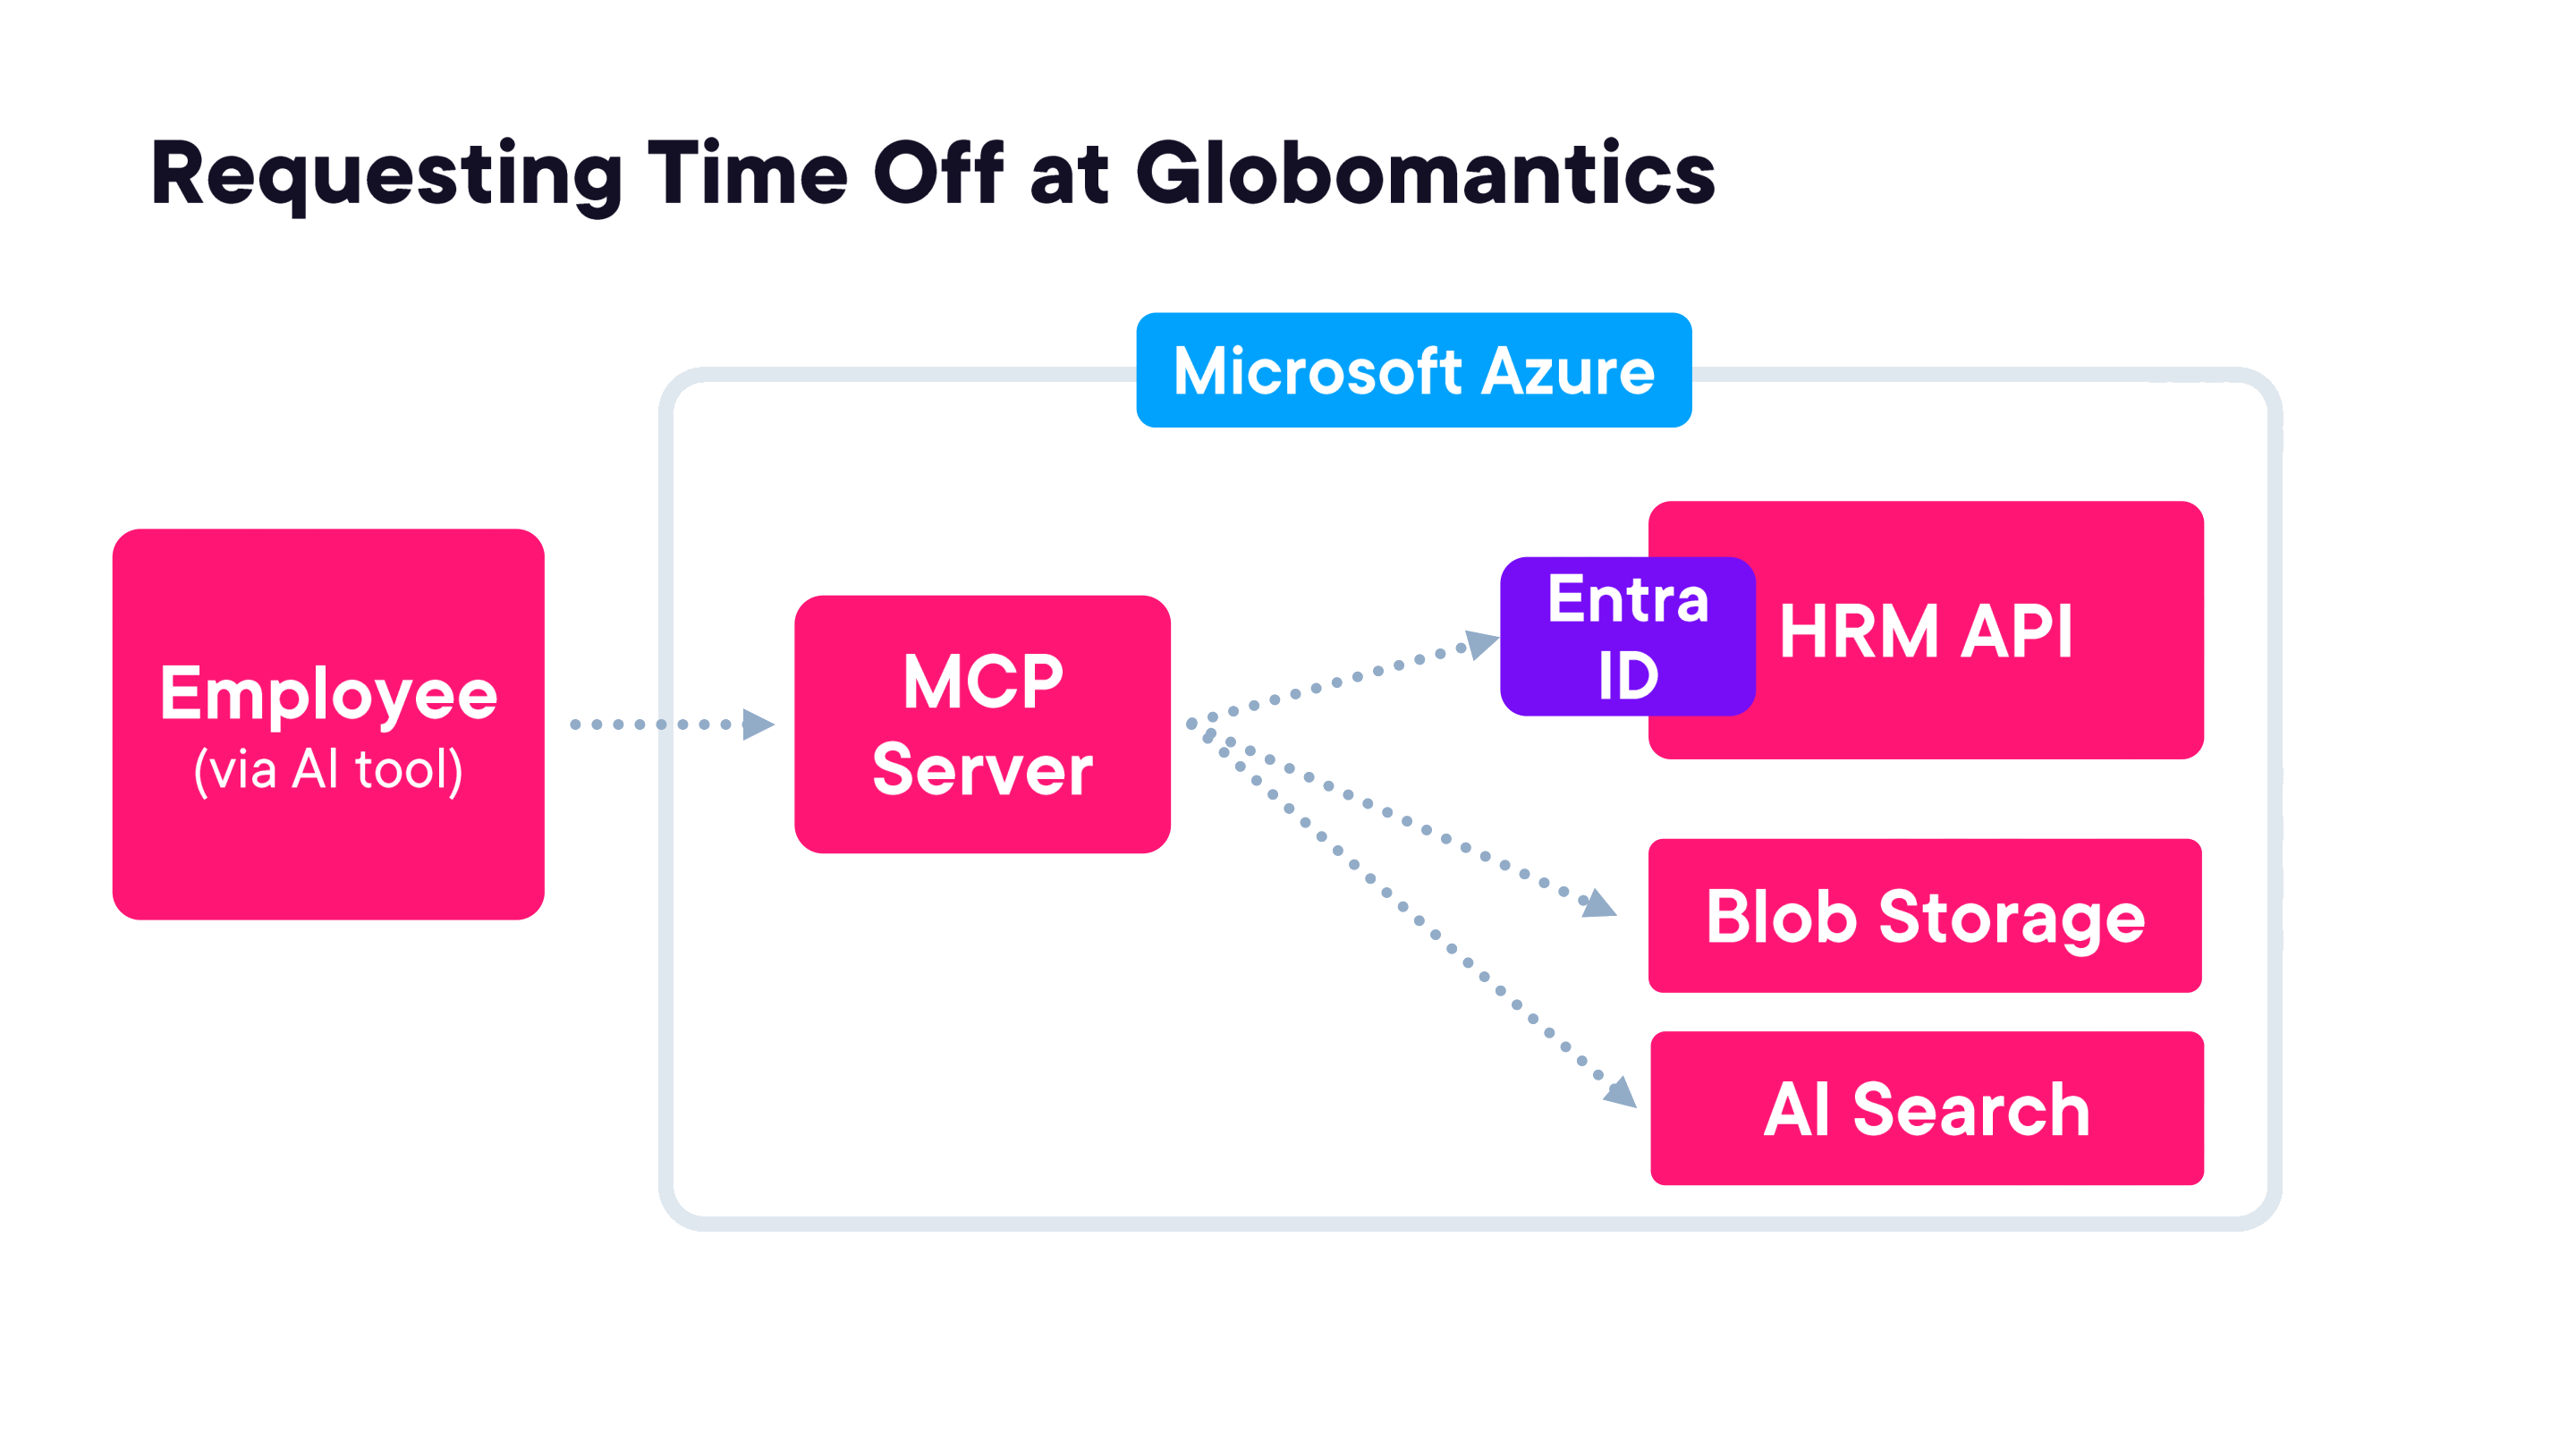

In [2]:
render_diagram(Path("assets/01-globomantics-full-architecture.png"))

### Environment Setup

The course uses TypeScript and C# side-by-side. Required tools:

- **Node.js 22** — for the TypeScript MCP SDK (`https://nodejs.org`)
- **.NET 8 and .NET 10** — for the C# MCP SDK (`https://get.dot.net`)
- **Claude Desktop** — AI client for testing (`claude.ai/download`)
- **Visual Studio Code** with GitHub Copilot — IDE (`code.visualstudio.com`)
- **Starship** — cross-shell prompt, optional (`https://starship.rs/`)

> There will be pre-release packages during the course — this is expected.

#### MCP Transport Specification References

- Transport spec: `https://modelcontextprotocol.io/specification/2025-06-18/basic/transports`
- Schema: `https://modelcontextprotocol.io/specification/2025-06-18/schema`

### Connecting Local MCP Servers to Clients

MCP clients that support local server connections include:

- **Visual Studio** — `learn.microsoft.com/en-us/visualstudio/ide/mcp-servers`
- **VS Code** — `code.visualstudio.com/docs/copilot/customization/mcp-servers`
- **Claude Code** — `docs.claude.com/en/docs/claude-code/mcp`
- **Cursor** — `docs.cursor.com/context/model-context-protocol`
- **JetBrains AI Assistant** — `www.jetbrains.com/help/ai-assistant/mcp.html`

### The MCP Inspector

The MCP Inspector is the primary debugging tool for MCP servers during development. It lets you connect to a local server and manually invoke tools, read resources, and test prompts without needing a full AI client.

- Inspector docs: `https://modelcontextprotocol.io/docs/tools/inspector`
- Lifecycle spec: `https://modelcontextprotocol.io/specification/2025-06-18/basic/lifecycle`

### Demo: Getting Started

See [`01-getting-started-demos/`](01-getting-started-demos/) for the full project collection used throughout this module.

The demo collection contains:

- **`m1-empty/`** — bare-bones C# MCP server scaffold to start from scratch
- **`m1-inspector/`** — MCP server configured for use with the Inspector, including `mcp.json` client config
- **`m2-stdio/`** — STDIO transport demo
- **`m2-token-counting/`** — TypeScript demo showing Anthropic token counting for MCP context management
- **`everything-demo/`** — complete Globomantics solution (.NET Aspire orchestrated): HRM API + MCP Server with tools, resources, prompts, and OAuth

## Module 02: Building MCP Servers

This module covers the three building blocks of an MCP server — **Resources**, **Tools**, and **Prompts** — by implementing a complete time-off management server for the Globomantics HRM system. It also covers context engineering, token management, and distribution strategies.

### Why MCP? Bridging Data to Answers

> Software fundamentally exists to bridge the gap from data to answers.

User interfaces have evolved over decades to reduce the friction between human intent and system response. MCP represents the next step in that trajectory — a **Contextual UI** where the interface is semantic inference rather than visual widgets:


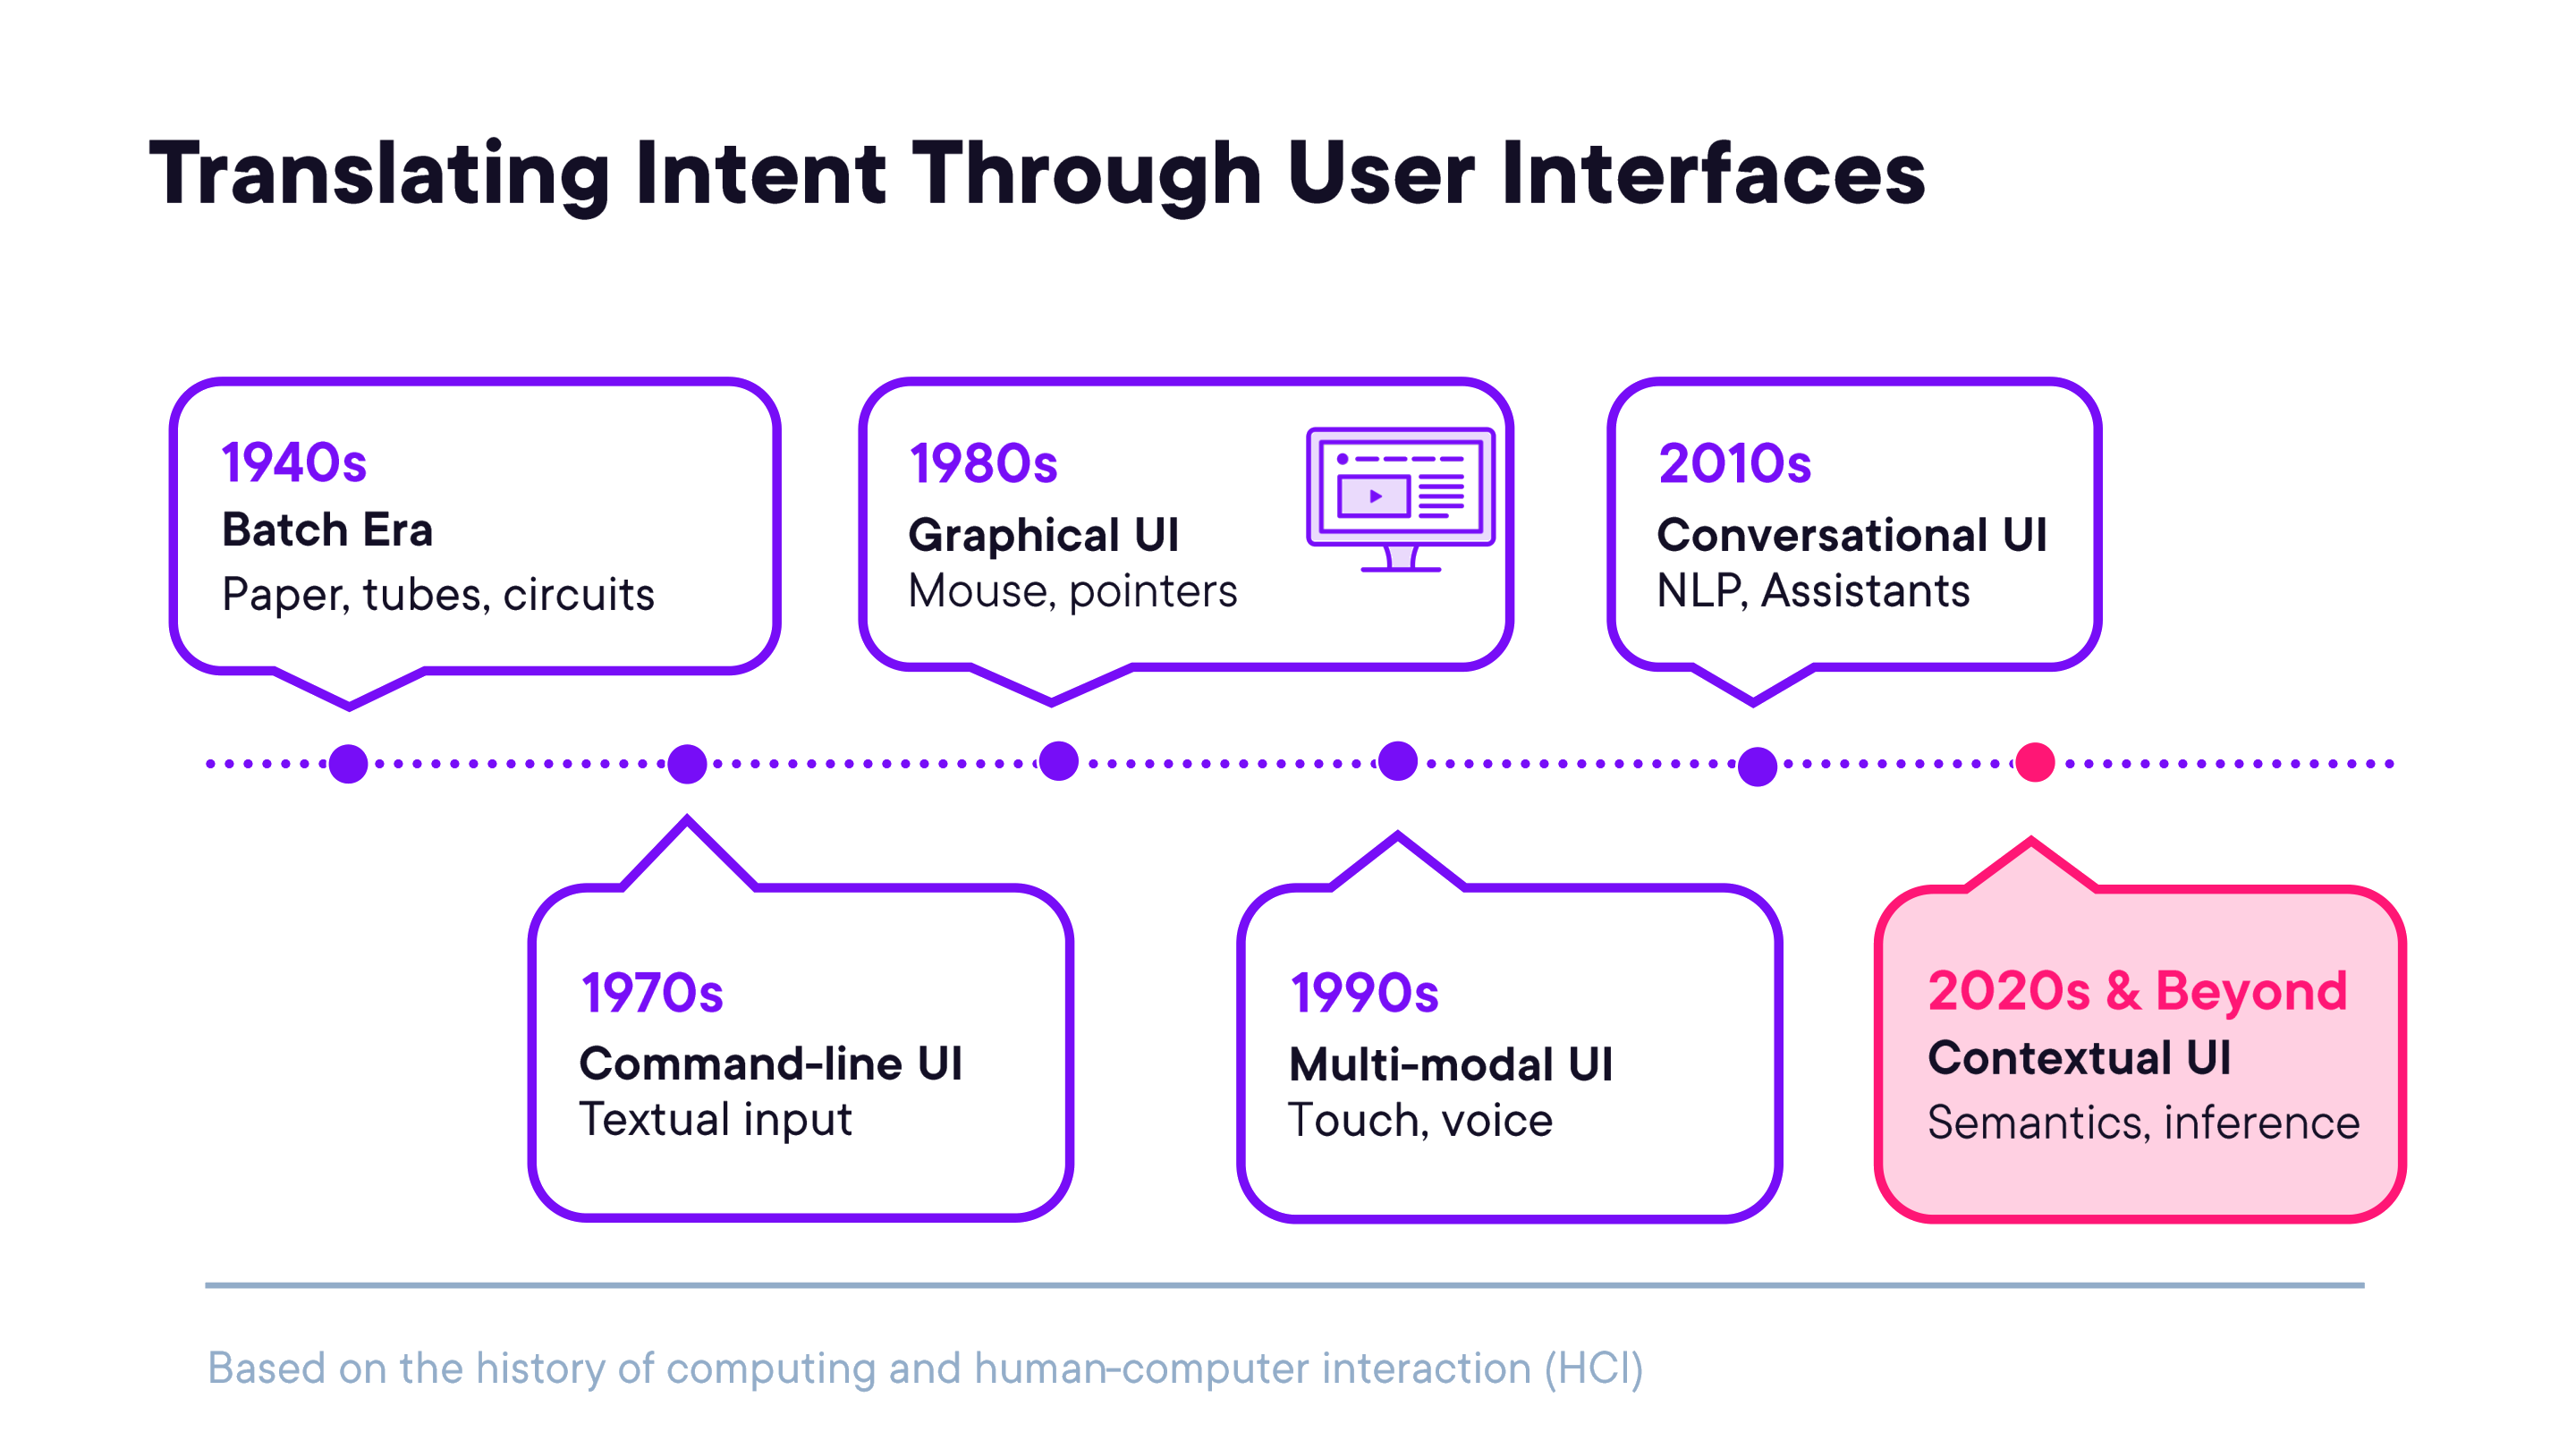

In [3]:
render_diagram(Path("assets/02-hci-timeline-evolution.png"))

### What Employees Actually Want

Employees asking HR questions don't think in terms of form fields. They ask natural questions:

- "When could I take my next vacation?"
- "How do I plan upcoming parental leave for a new child?"
- "Am I eligible for a sabbatical?"
- "Will I have enough accrued balance for a future trip?"
- "My doctor said I have to take leave. How does that work?"

An MCP server exposes the HRM system's data and operations in a way that an AI can use to answer these questions directly.

### Why Build an MCP Server?

Goal: **Help employees plan time off and reduce workload for HR.** Three capability areas:

| Capability | Description |
|---|---|
| **Absence Requests** | Workflow for requesting time off and checking eligibility |
| **Dynamic Calendar** | Access work calendar based on employee location |
| **Benefit Plans** | Access to specific plan documentation |

### Where to Find the Data?

The HRM system exposes data through multiple sources. In Phase 1 (direct API access):

| Data | Source | Format |
|---|---|---|
| Worker Info | REST API | JSON |
| Planned Time Off | REST API | JSON |
| Request Time Off | REST API | JSON |
| Plan Documents | Blob Storage | PDF |
| Policy Documents | Blob Storage (hardcoded) | PDF |
| Office Calendars | Hardcoded | Code |

### Globomantics MCP Server Blueprint

The complete server exposes:

| Resources | Tools | Prompts |
|---|---|---|
| Calendars | Request Time Off | Suggest Time Off |
| Documents | Get Time Off | Next Scheduled Holiday |
| | Plan Time Off | |
| | Ask About Policy | |

### Resources

Resources are read-only data sources the LLM can access. They come in two flavours:

- **Static resources** — fixed URIs (e.g. `calendar://offices/london`)
- **Resource templates** — URI templates with parameters (e.g. `timeoff://{employeeId}/planned`)

Resources do not execute side effects; they supply context to the model.

#### Resource Templates

Resource templates allow parameterised URIs. The server registers a template pattern and resolves it at request time. This is how employee-specific data (planned time off, work calendars) is exposed dynamically.

### Tools

Tools are the actions the LLM can invoke. Unlike Resources, tools may have side effects (e.g. submitting a time-off request to the HRM API).

#### Tool Input Schemas

Every tool must declare its input schema. Languages with reflection support automatic schema generation; others require manual schema definition:

| Automatic schema generation | Manual schema required |
|---|---|
| Python | JavaScript / TypeScript |
| C# | Kotlin |
| Go | Java |
| Rust | Ruby |
| PHP | Swift |

In TypeScript, use the **Zod** library to define schemas:

In [4]:
# TypeScript — Zod input schema definition
zod_example = """
import { z } from 'zod';

server.registerTool(
    'add',
    {
        title: 'Addition Tool',
        description: 'Add two numbers',
        inputSchema: { a: z.number(), b: z.number() },
    },
    async ({ a, b }) => {
        const output = a + b;
        return {
            content: [{ type: 'text', text: output.toString() }],
        };
    }
);
"""
print(zod_example)


import { z } from 'zod';

server.registerTool(
    'add',
    {
        title: 'Addition Tool',
        description: 'Add two numbers',
        inputSchema: { a: z.number(), b: z.number() },
    },
    async ({ a, b }) => {
        const output = a + b;
        return {
            content: [{ type: 'text', text: output.toString() }],
        };
    }
);



#### Tool Content Block Types

A tool can return different content types in its response:

- **Text** — plain or structured text
- **Image** — base64-encoded image data
- **Audio** — base64-encoded audio data
- **Resource Link** — a URI reference the client can follow
- **Embedded Resource** — inline resource content

#### Tools: Structured Content

Tools can return structured JSON output in addition to text content. This enables the client or LLM to process the result programmatically.

#### The `request-time-off` Tool Flow

The simplest tool takes employee-supplied inputs, calls the HRM API, and returns a structured result to the LLM:


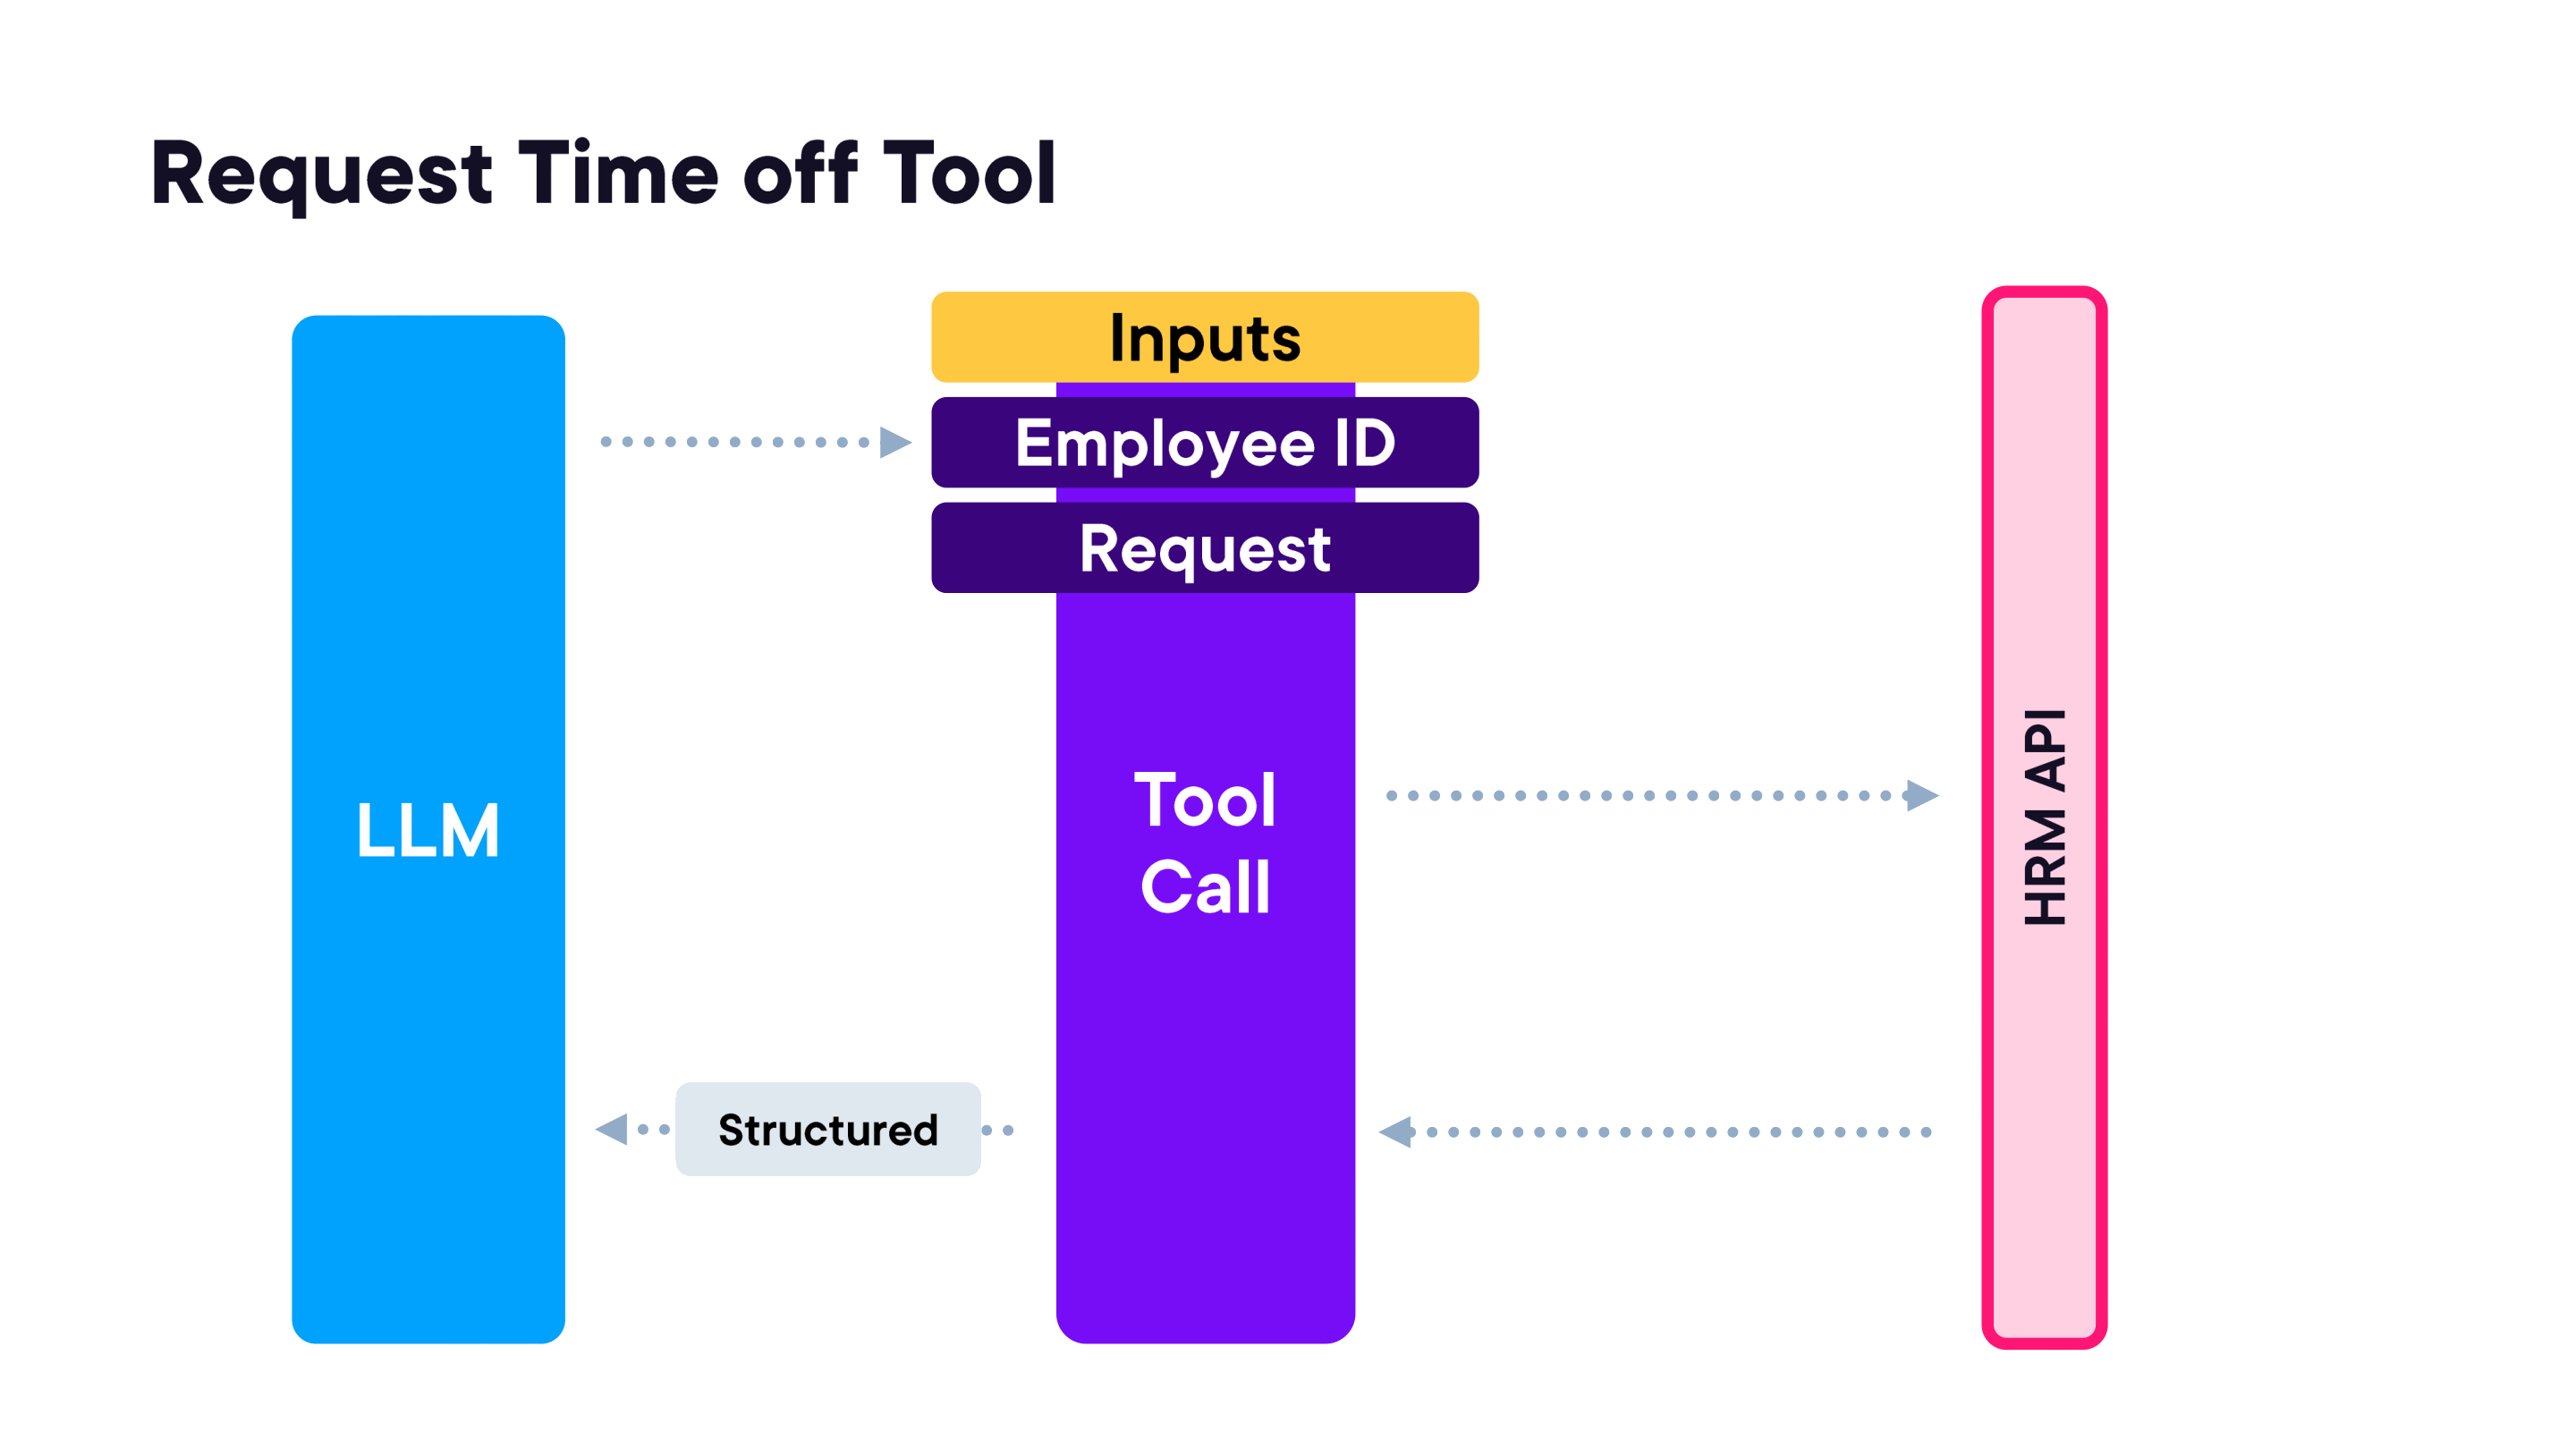

In [5]:
render_diagram(Path("assets/04-request-timeoff-tool-flow.png"))

#### Improving Tool Calling Capability

Design choices that improve the LLM's ability to use tools correctly:

- **Simplify, flatten, or consolidate parameters** — fewer, clearer inputs work better than a complex object hierarchy
- **Support fuzzy data or provide user-friendly abstraction** — accept date ranges in natural forms, not just ISO timestamps
- **Provide clear, directed instructions** — tool descriptions are prompt engineering
- **Wrap error messages with context** — return actionable errors, not raw API failures

#### Tools: Embedded Resources

A tool response can embed resource content directly in its output, so the LLM has the data inline rather than needing a separate resource fetch.

#### The `get-time-off` Tool Flow

This tool gathers *personalised* context for the LLM: it fetches the employee's planned time off (via HRM API) and their work calendar, and attaches them as embedded resources alongside employee details and HR documents:


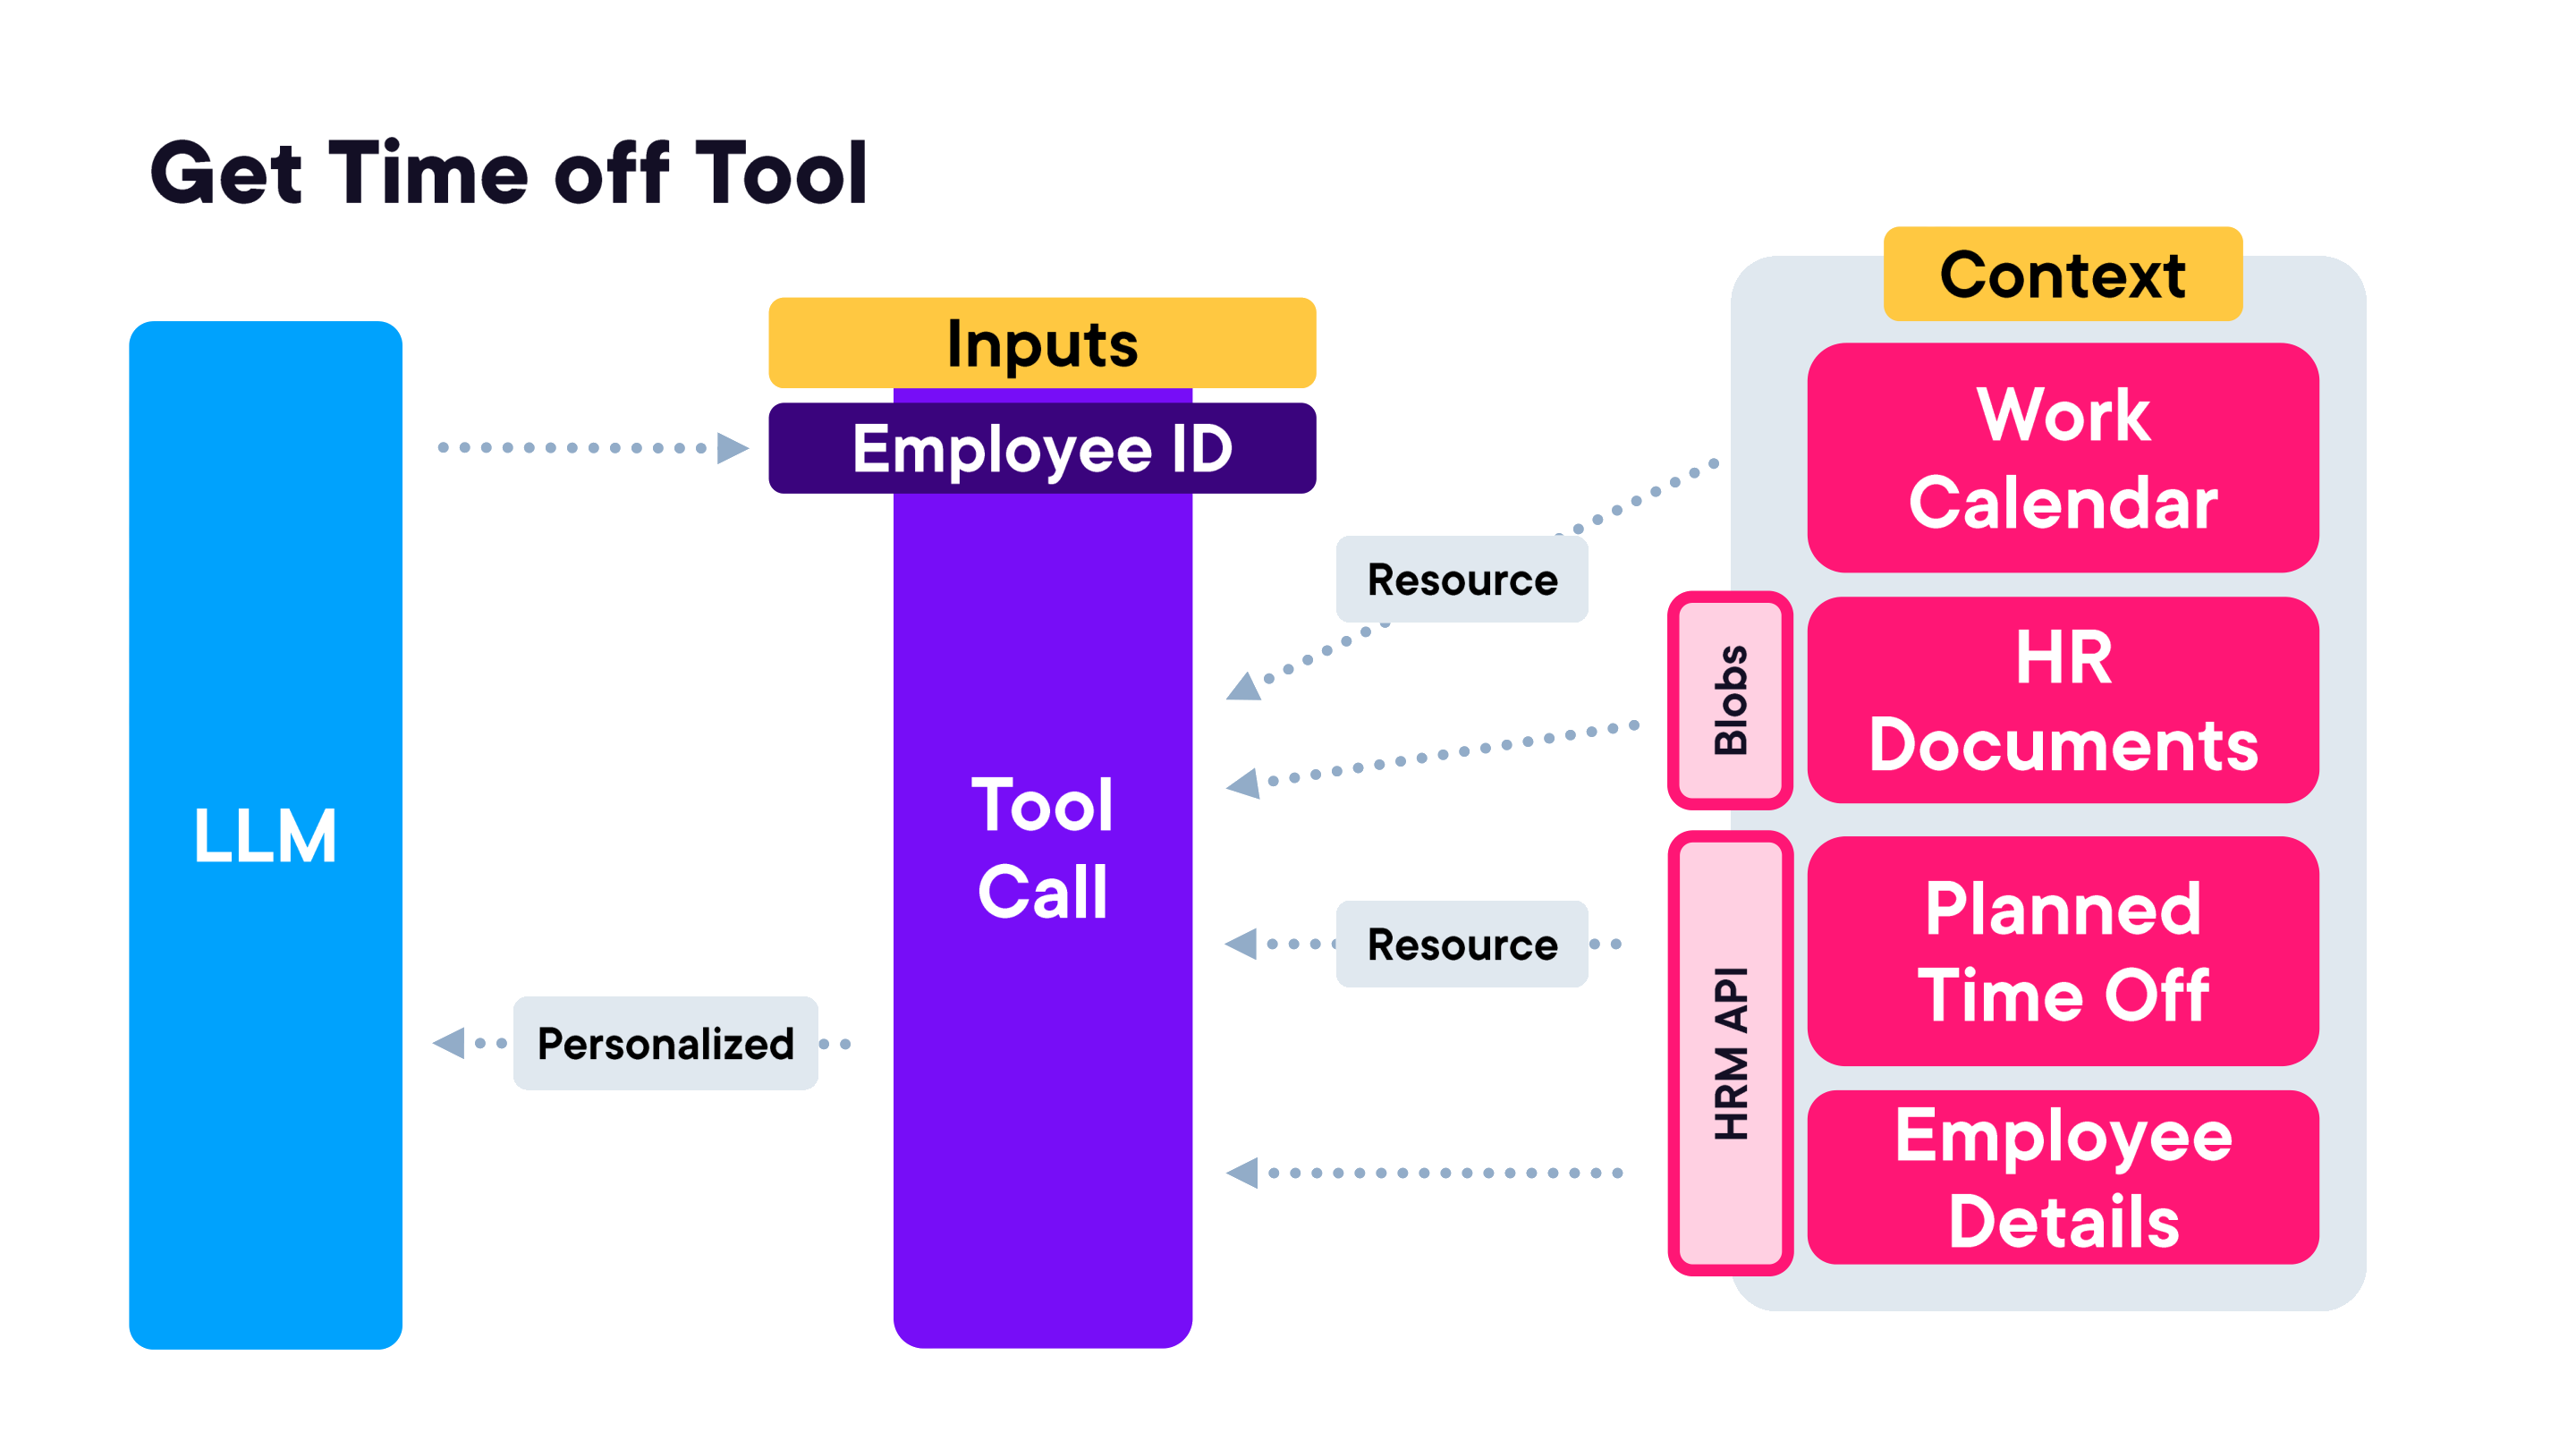

In [6]:
render_diagram(Path("assets/05-get-timeoff-tool-flow.png"))

#### Tools: Context Engineering

> Context Engineering: Building dynamic systems to provide the right information and tools in the right format such that the LLM can plausibly accomplish the task.
>
> — blog.langchain.com/the-rise-of-context-engineering

#### Reducing Token Usage

Context size directly affects cost and performance. Key strategies:

- Use **concise LLM-facing descriptions** — verbose tool descriptions consume context budget
- **Avoid embedding large (>5 KB) resources** — prefer linked resources or summaries
- **Only include relevant output** and limit serialising objects
- Provide a **Resource size hint** so clients can estimate context usage
- Use **Agentic Retrieval or RAG vector search** for large knowledge bases rather than embedding full documents

#### The `plan-time-off` Tool Flow

The planning tool extends `get-time-off` by also querying **AI Search** (Azure Cognitive Search) over the blob storage of HR documents — enabling retrieval-augmented generation for policy questions:


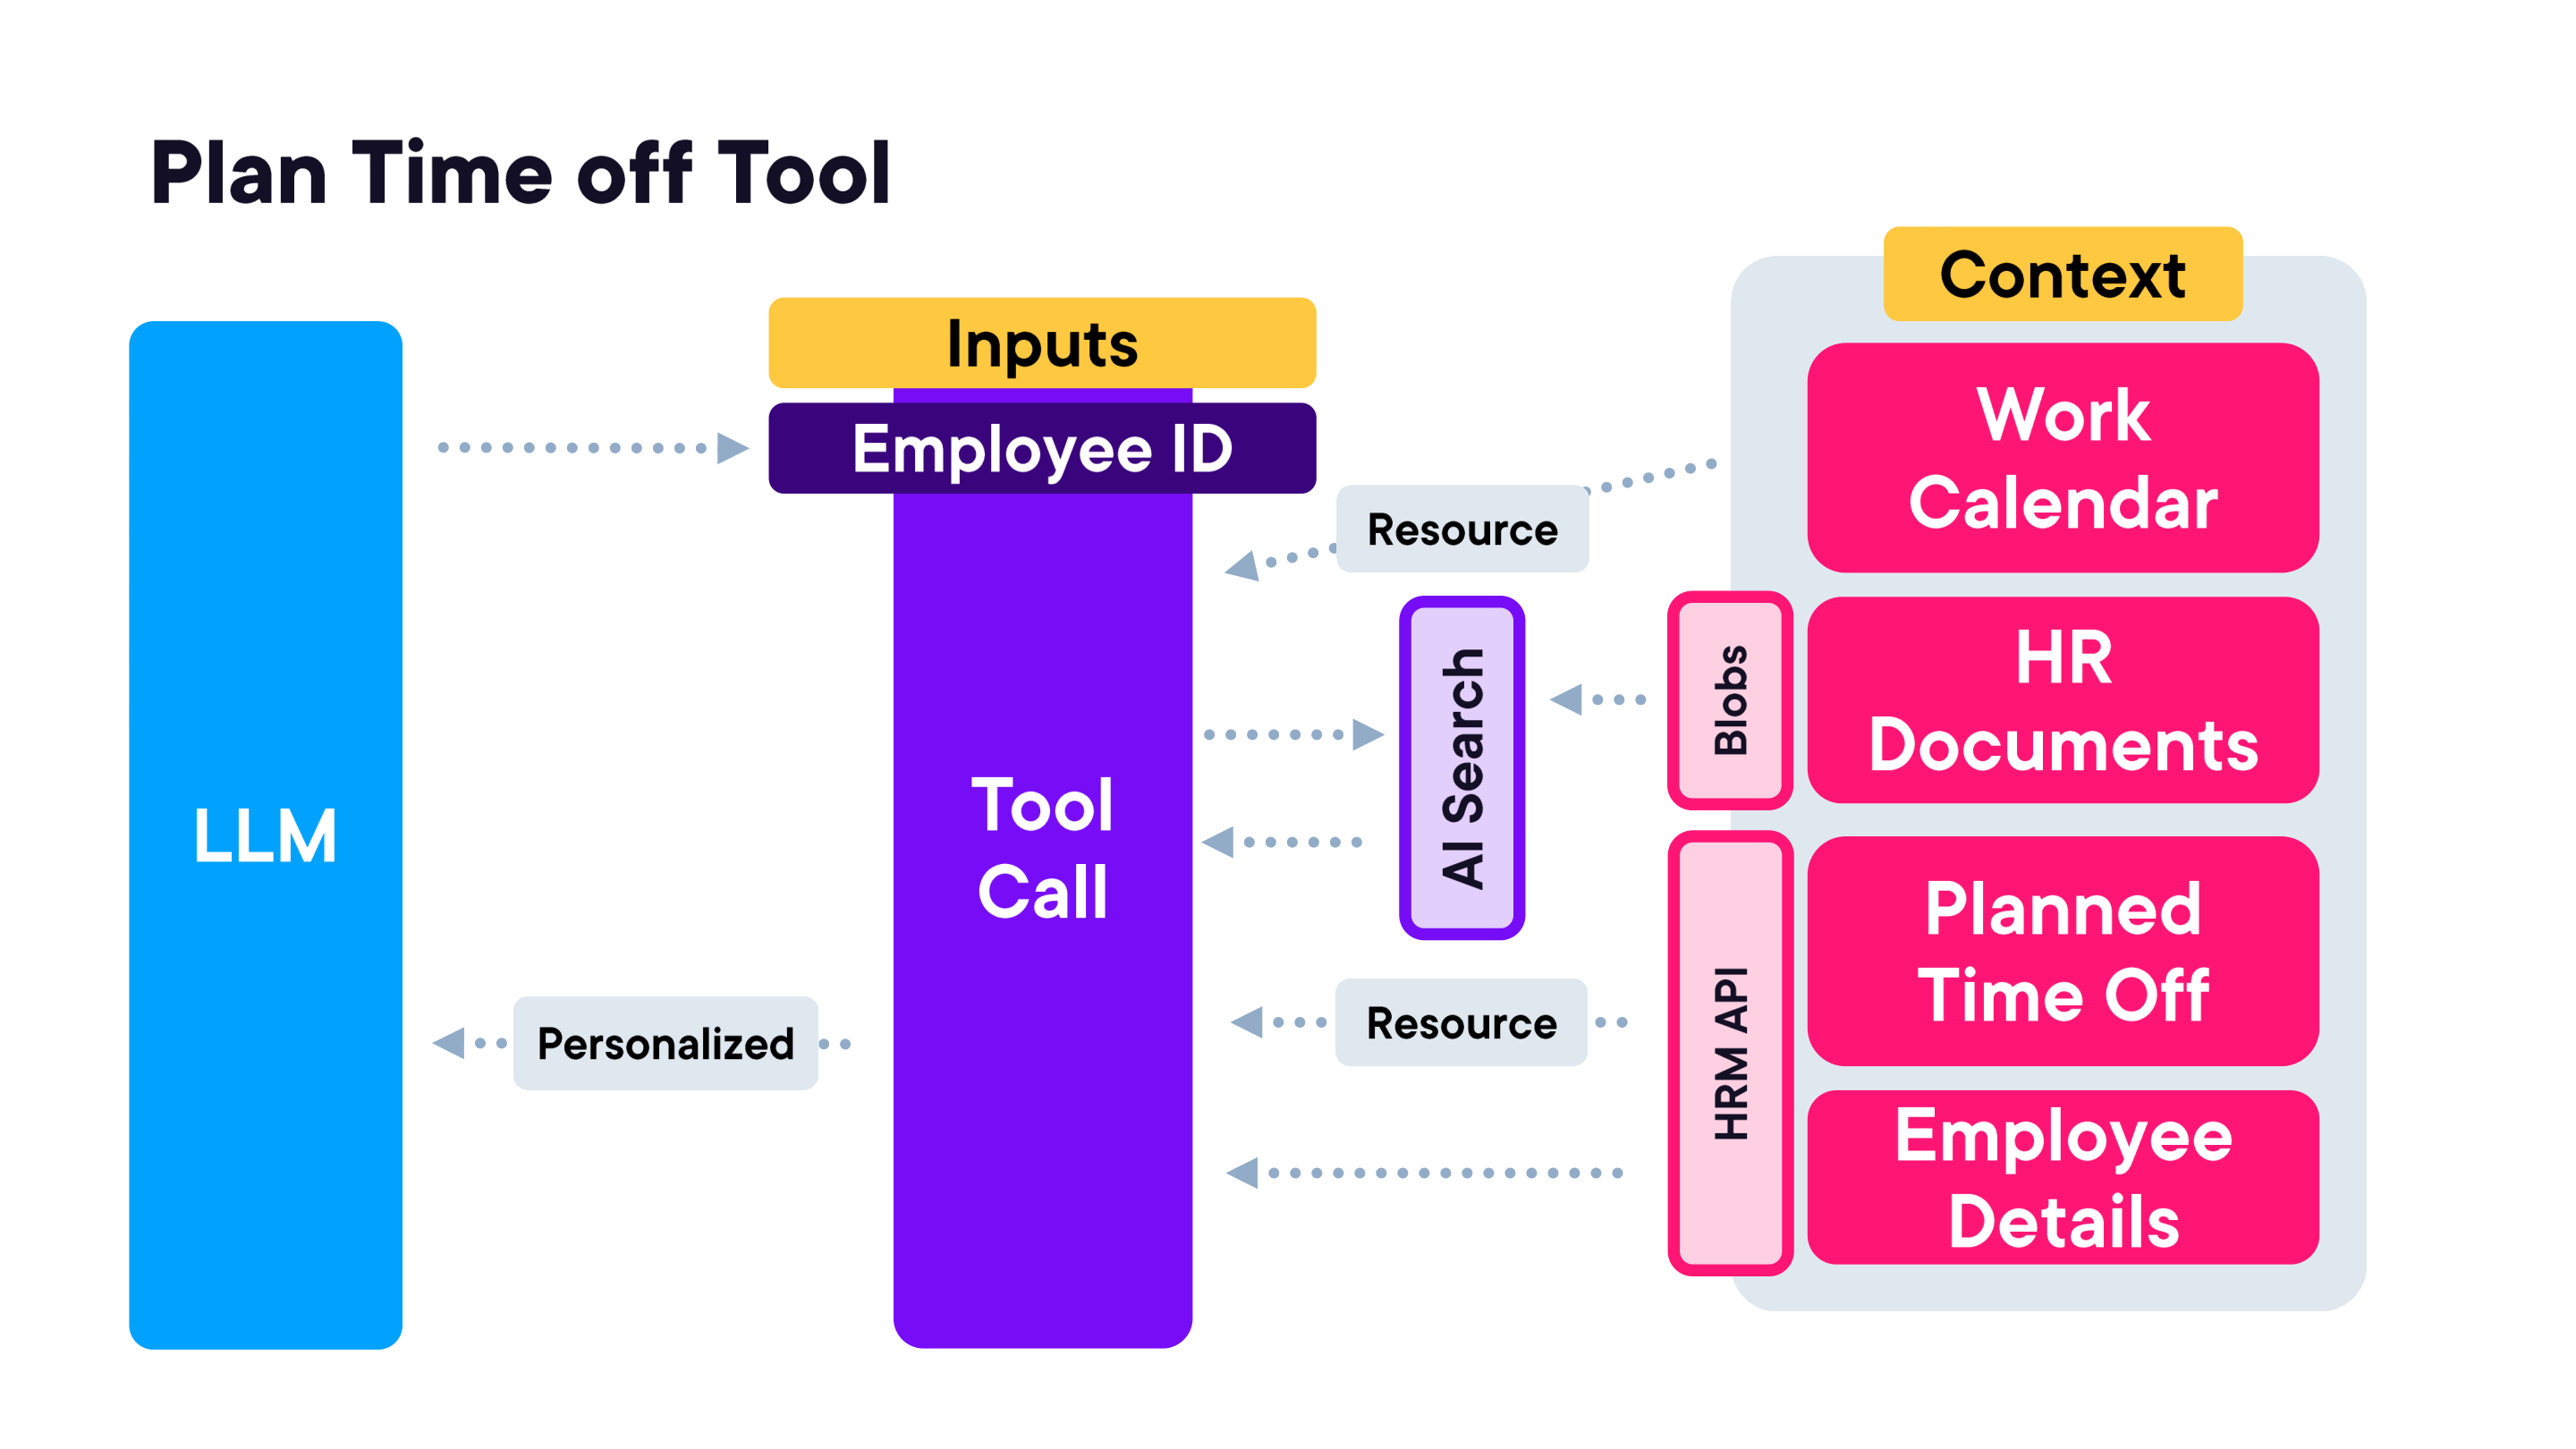

In [7]:
render_diagram(Path("assets/06-plan-timeoff-tool-flow.png"))

Multi-modal PDF vectorization reference for Azure AI Search: `learn.microsoft.com/en-us/azure/search/tutorial-document-layout-multimodal-embeddings`

### Prompts

Prompts are reusable, parameterised conversation starters that clients can surface in their UI. They differ from tools in that they don't execute operations — they produce a message sequence for the LLM.

Prompt features:
- Can include **roles** (system, user, assistant) to frame the conversation
- Can embed **resource content** as part of the messages
- Can accept arguments to personalise the prompt at call time

The Globomantics server defines:
- **`suggest-time-off`** — helps the employee find a good window based on calendar and balance
- **`ask-about-policy`** — guides the employee through HR policy questions using embedded documents

### Distributing Local MCP Servers

Local MCP servers must be distributed to end-users. Common mechanisms:

| Method | Requires |
|---|---|
| Node / npx | Node.js installed |
| Docker | Docker installed |
| .NET / dnx | .NET runtime installed |
| Python / uv | Python + uv installed |
| Any language package | Platform tools installed |
| **Standalone executable** | Nothing — runs anywhere |

Most methods require extra software on the end-user's machine. **Standalone executables** are the most portable option.

#### Distribution Methods Overview


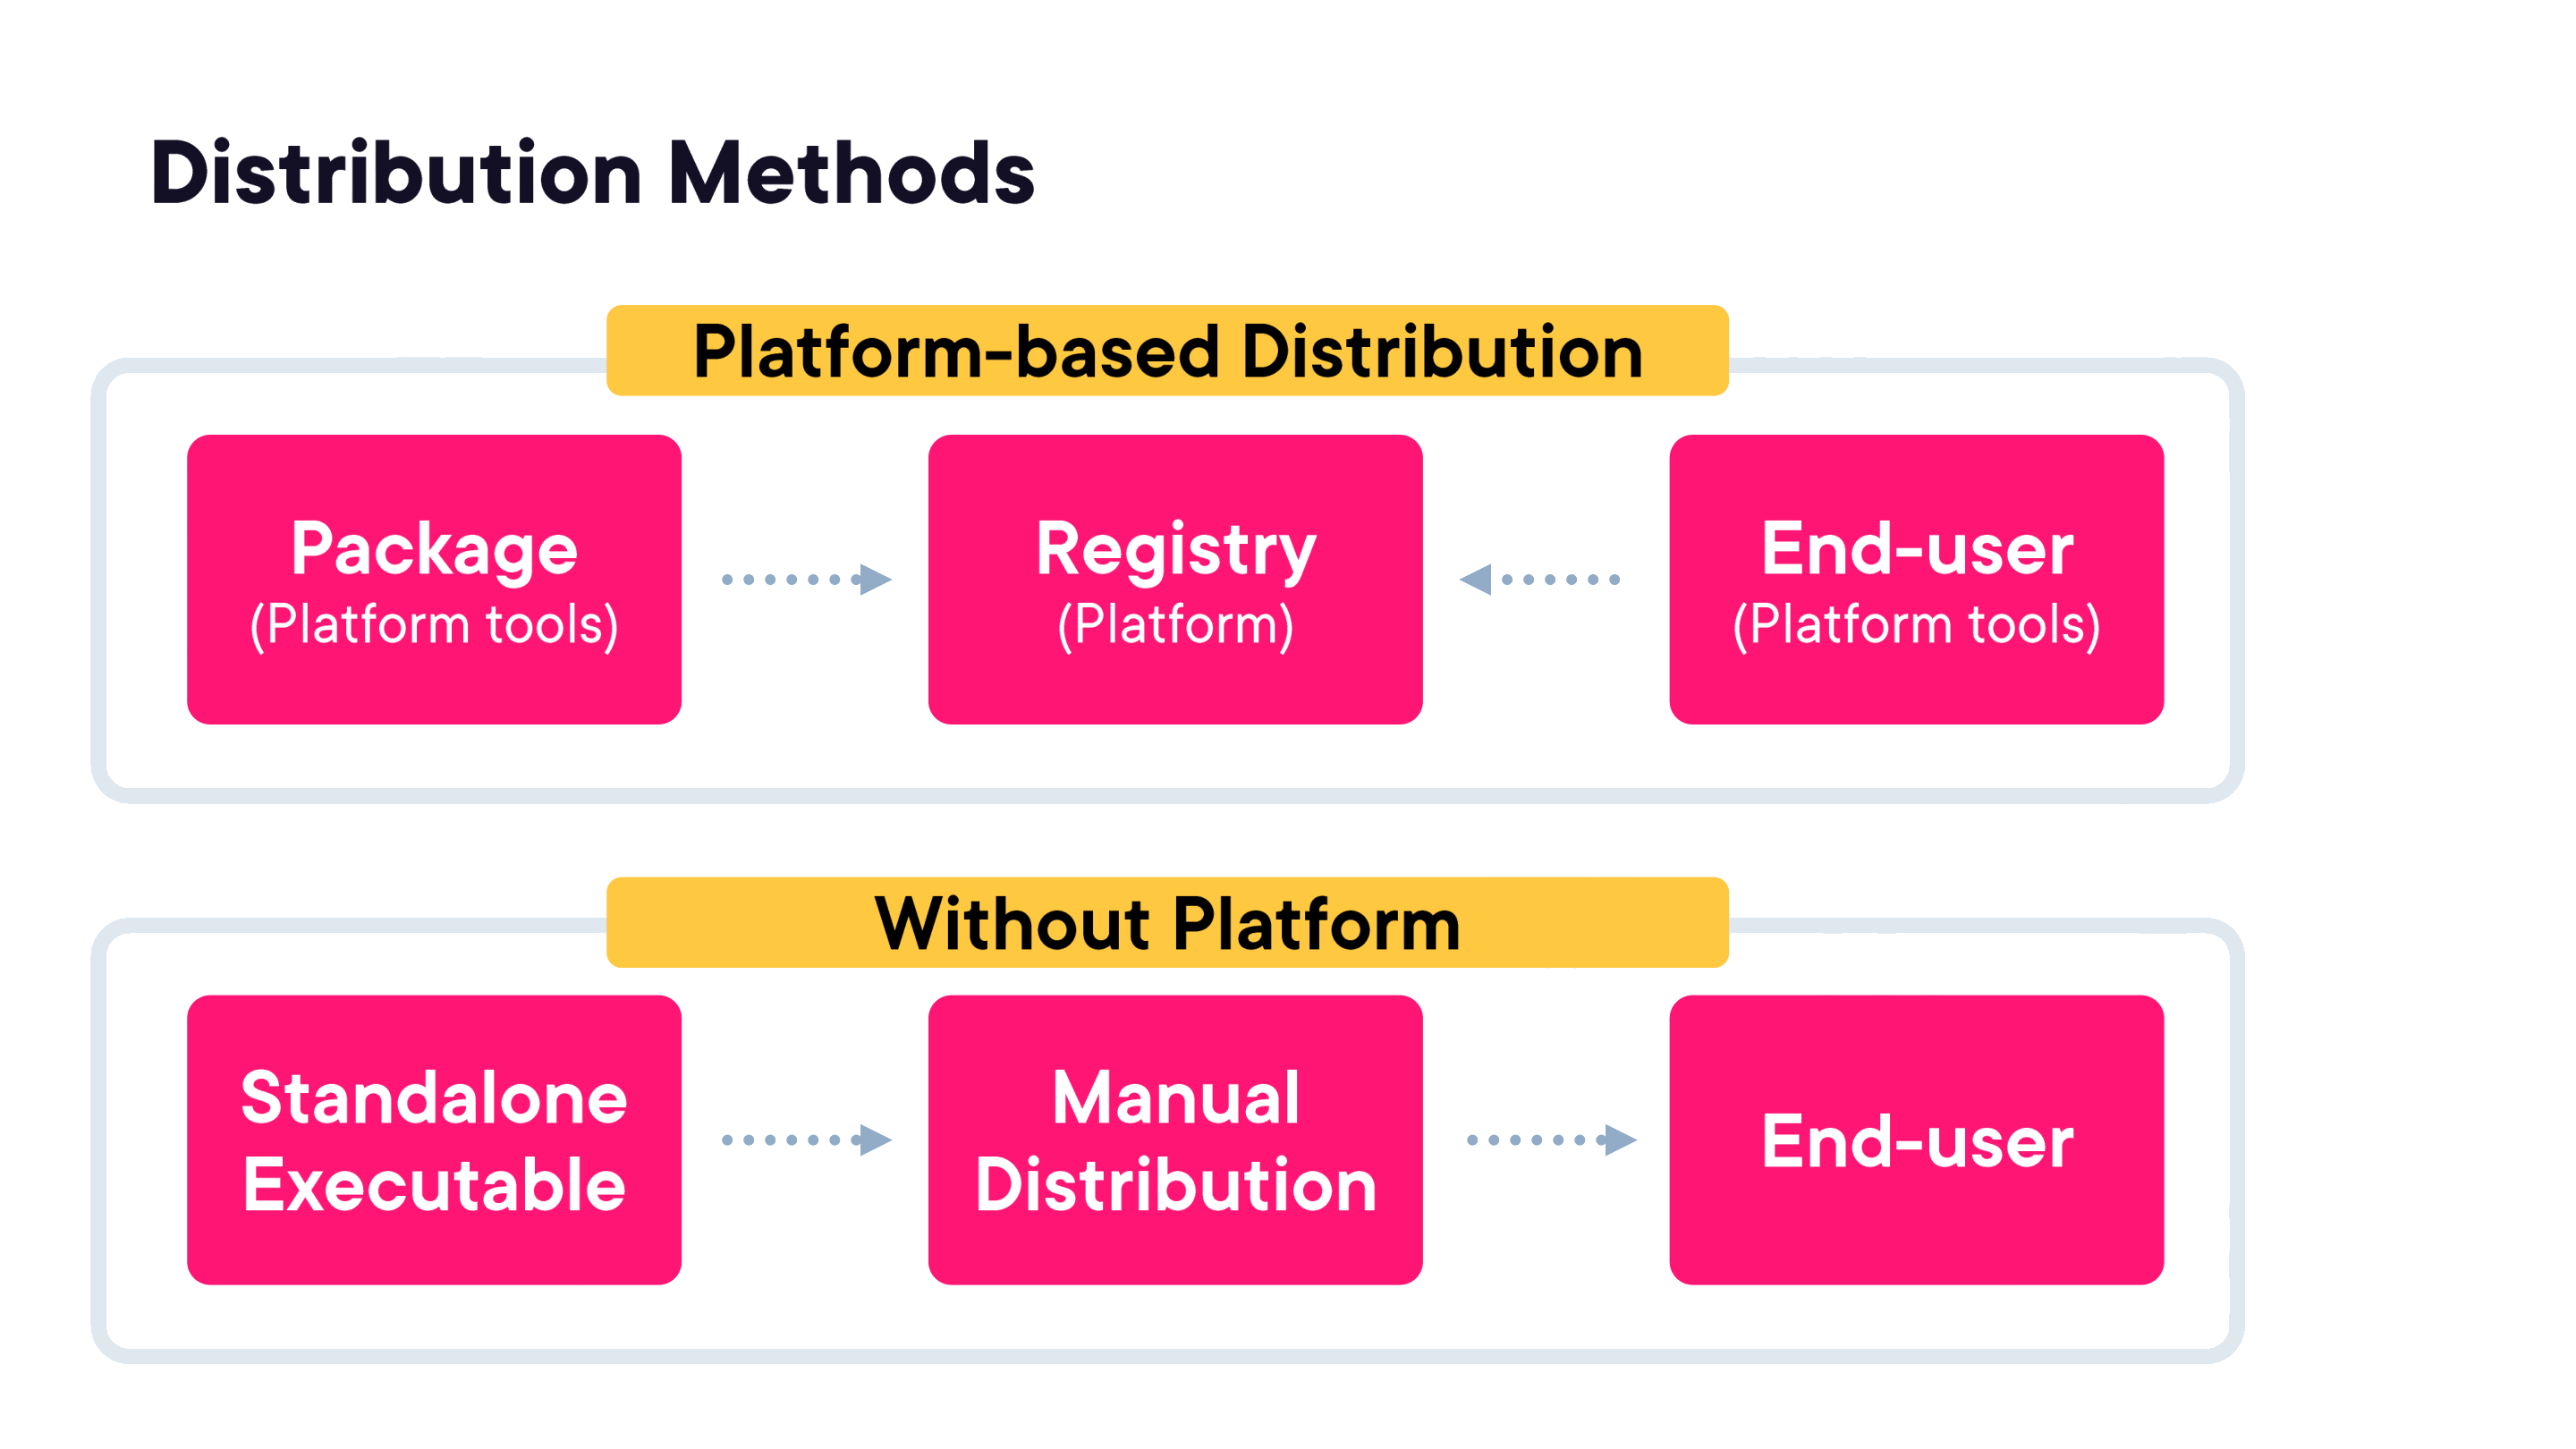

In [8]:
render_diagram(Path("assets/07-distribution-methods.png"))

#### Standalone Executable References

- Azure MCP Server (example): `github.com/microsoft/mcp/blob/main/servers/Azure.Mcp.Server`
- Node.js single executable: `github.com/nodejs/single-executable`
- .NET single-file publishing: `learn.microsoft.com/en-us/dotnet/core/deploying/single-file/overview`
- .NET Native AOT: `learn.microsoft.com/en-us/dotnet/core/deploying/native-aot`
- Microsoft.Extensions.AI Templates: `www.nuget.org/packages/Microsoft.Extensions.AI.Templates`

### Security Note: The Unauthenticated Server

At the end of this module, the Globomantics MCP server exposes all tools and resources with no authentication. Any caller can request time off on behalf of any employee by supplying an employee ID. This is the **security hole** addressed in Module 04.

## Module 03: Remote MCP Servers

This module covers converting a local STDIO-based MCP server to a remote HTTP server, choosing a hosting strategy, and deploying to Azure. It introduces the Streamable HTTP transport and discusses the trade-offs between local and remote deployment.

### Local vs. Remote MCP Servers

| | Remote MCP Server | Local MCP Server |
|---|---|---|
| **Runs on** | Remote machine | Your local machine |
| **Transport** | Must use HTTP | STDIO or HTTP |
| **Local resource access** | No | Yes |
| **Client configuration** | Easier (one URL) | Requires distribution |
| **Hosting complexity** | Higher | Lower |
| **OAuth support** | Yes | Yes |

> There is no "best" way to host an MCP server. It depends on the use case.

### Authentication Evolution

The server moves through three authentication phases:

**Phase 1 — Anonymous (local, STDIO):** The server uses system credentials to access Azure. The employee identity is not passed through.

**Phase 2 — OAuth (local, STDIO):** The employee authenticates via OAuth; the server uses delegated identity to call Azure on their behalf.

**Phase 3 — OAuth (remote, HTTP):** Same delegated identity, but the server is now hosted on Azure and accessed over HTTP by any MCP client.

### Using the Streamable HTTP Transport

The Streamable HTTP transport is the required transport for remote MCP servers. It supports:
- Standard HTTP request/response for single-turn tool calls
- Server-Sent Events (SSE) for streaming responses
- Stateful sessions (optional)

Reference: Stateful HTTP — MCP Advanced Features course.

### Hosting Remote MCP Servers

There is no single prescribed hosting strategy. Common options depend on whether the use case needs stateful sessions, scale-out, or tight Azure integration.

### Deploying: Lift and Shift

The simplest deployment takes the existing local server and moves it to Azure with minimal changes — swapping STDIO transport for HTTP. The server still uses system credentials (no OAuth yet):

### Anonymous Remote MCP Server


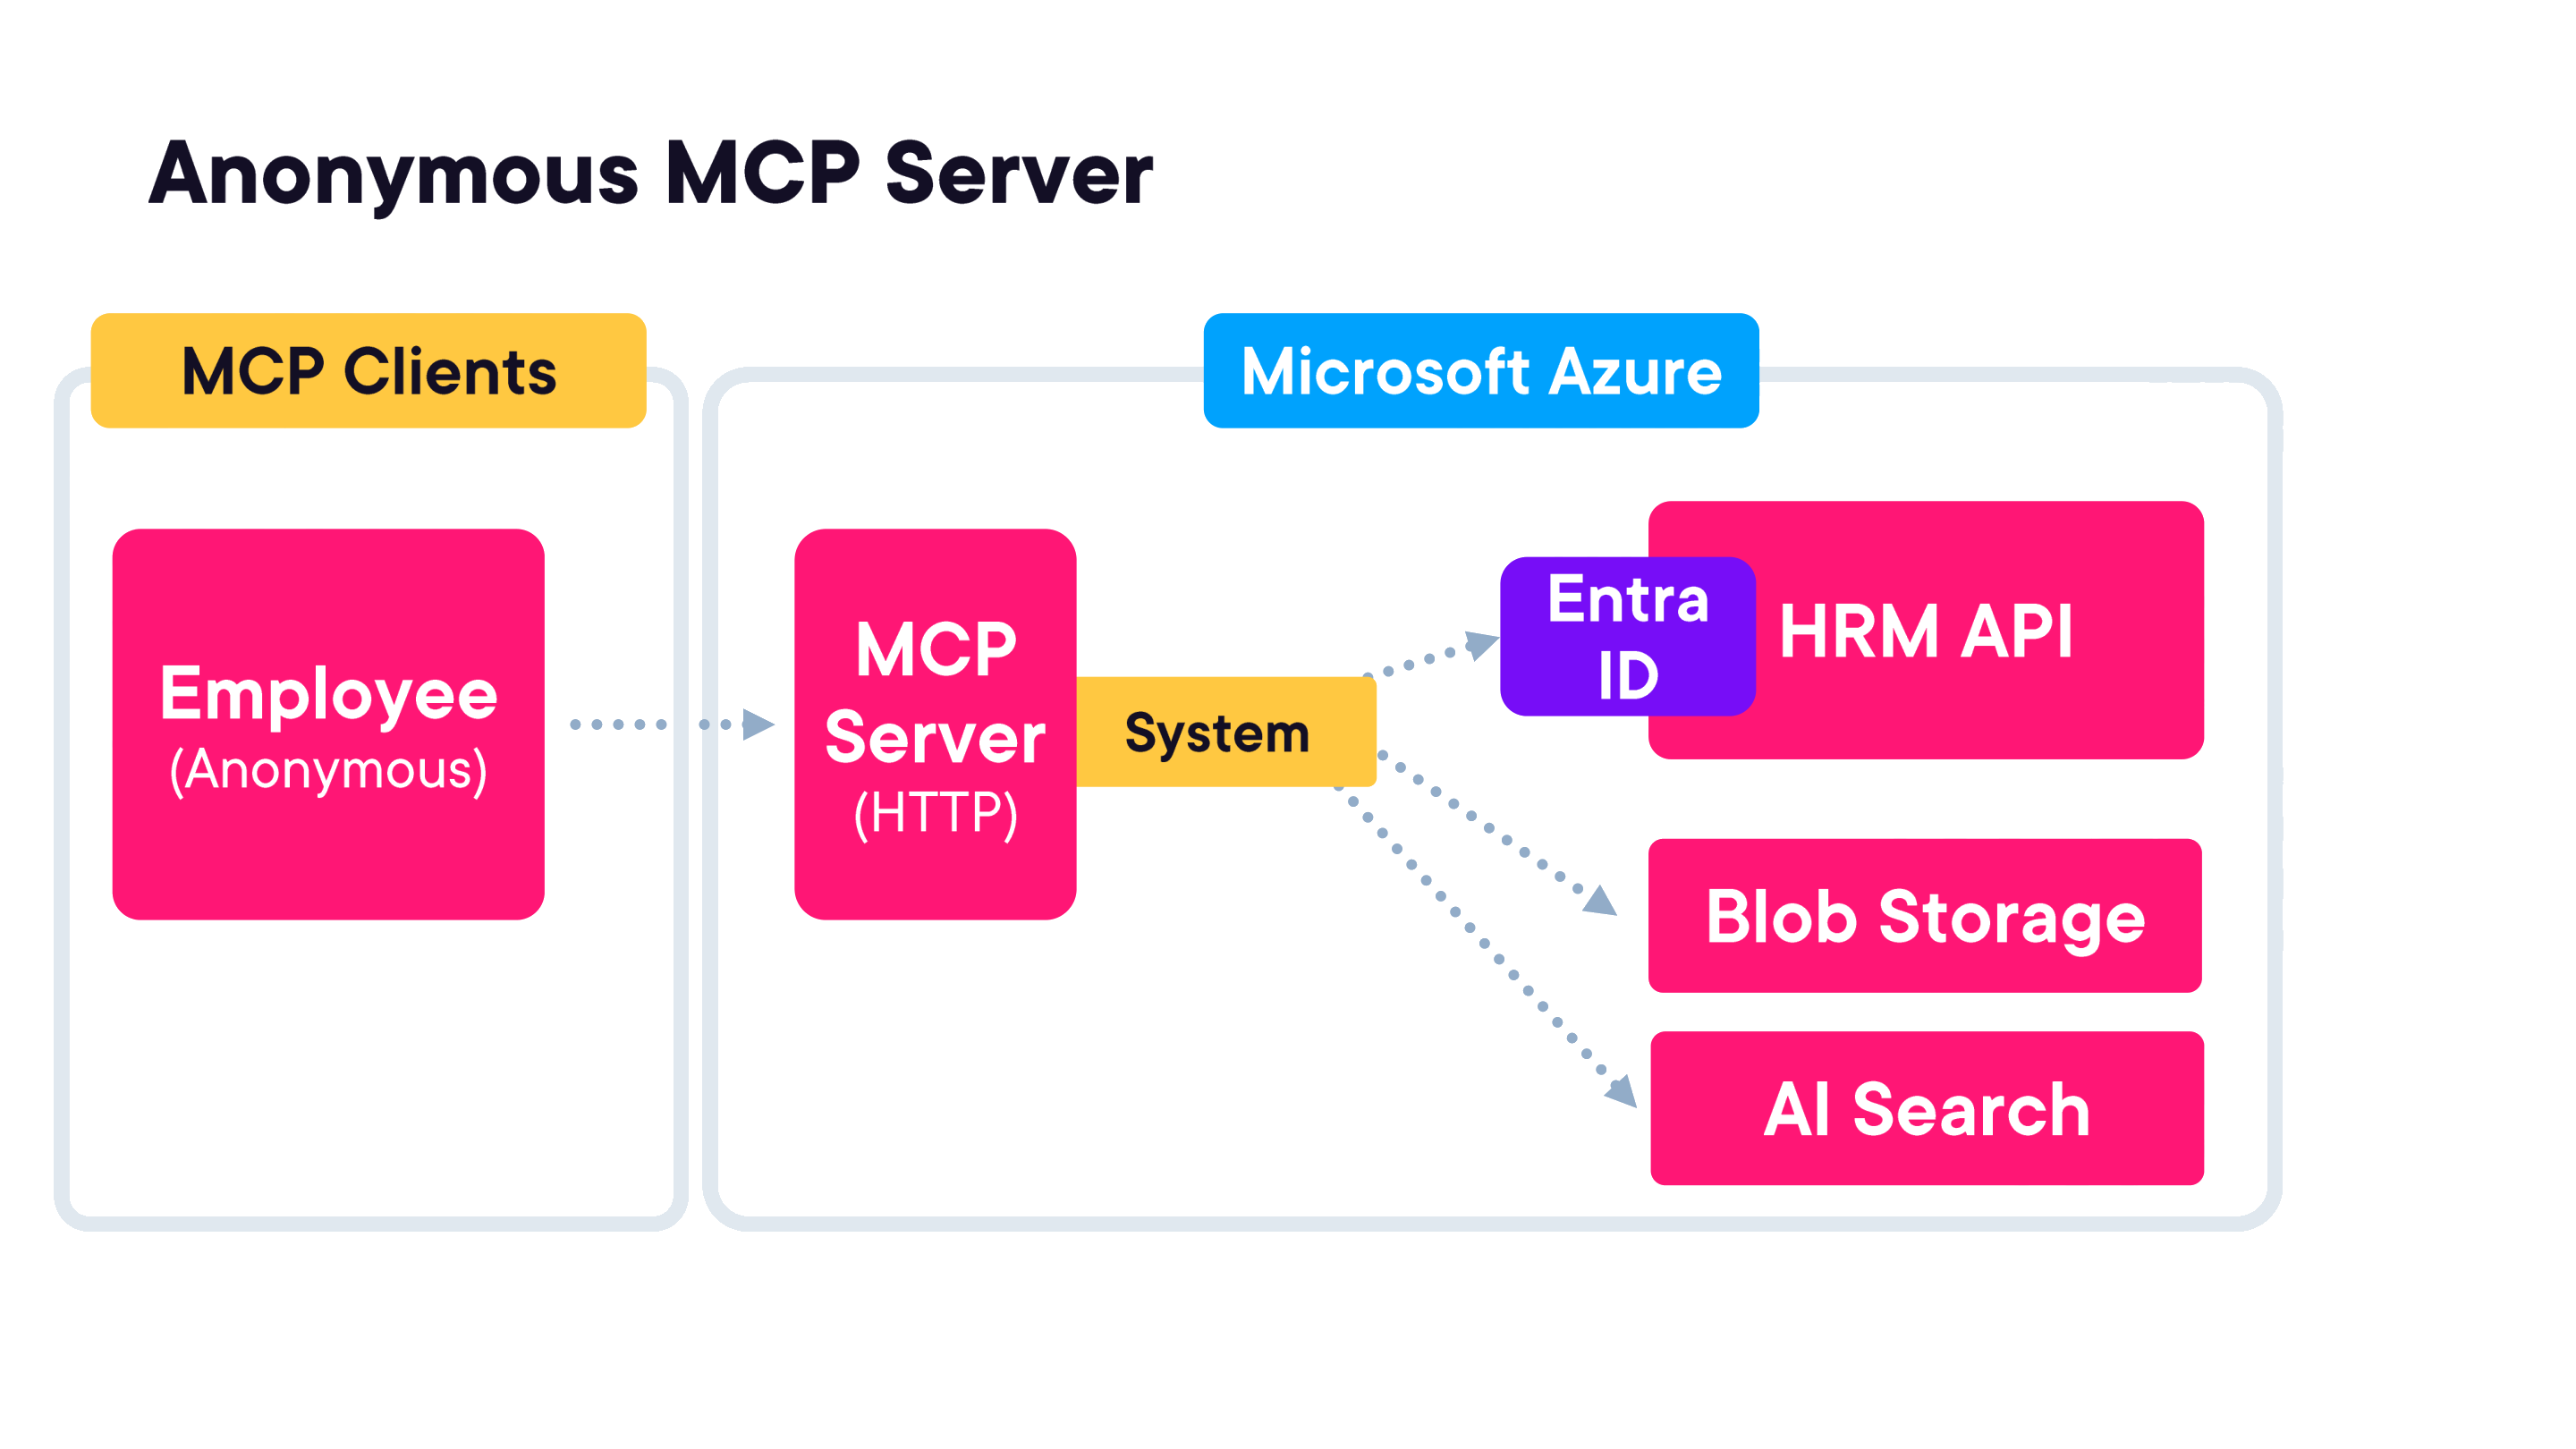

In [9]:
render_diagram(Path("assets/09-anonymous-mcp-server-deployment.png"))

The anonymous remote server accepts connections from any MCP client. The server authenticates to Azure services using a **system identity** (e.g. Managed Identity) — no per-user identity is involved. This is appropriate for read-only or non-sensitive workloads.

### Protected Remote MCP Server (with Delegated Identity)


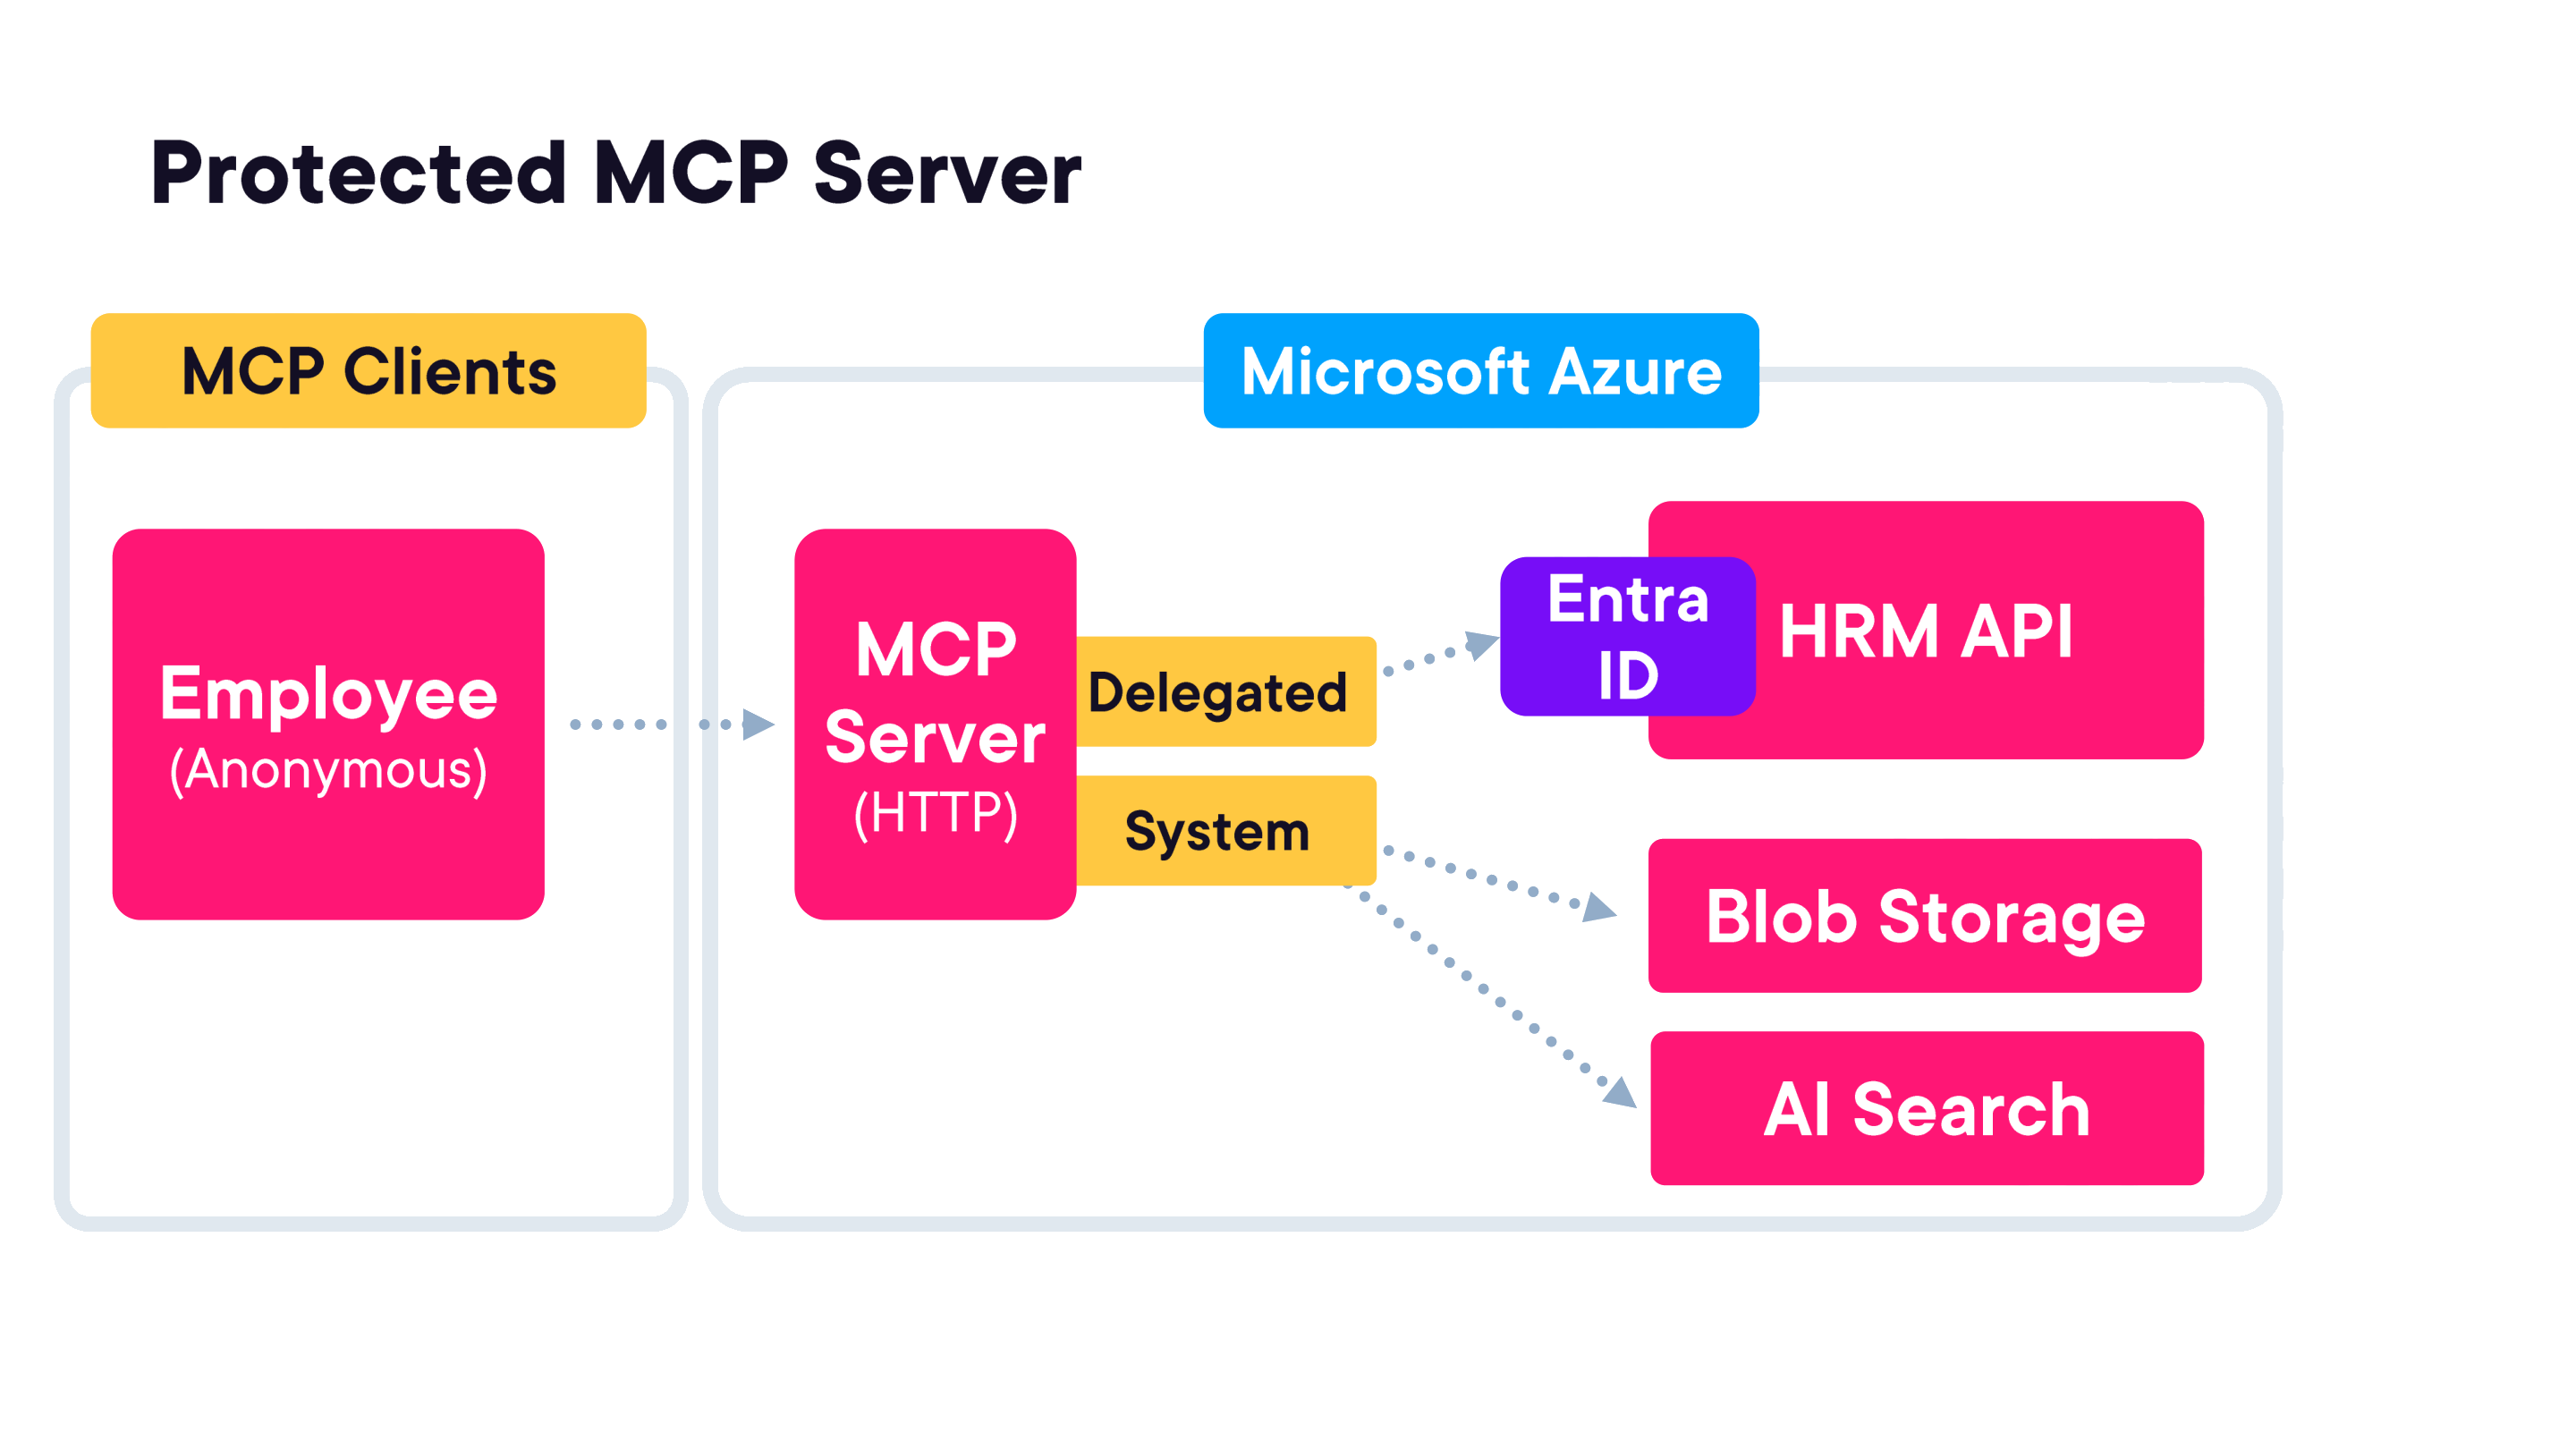

In [10]:
render_diagram(Path("assets/10-protected-mcp-server.png"))

The protected server uses two credential channels:
- **Delegated** — the employee's own identity (via OAuth bearer token) to access the HRM API
- **System** — a managed identity for non-user-specific services (Blob Storage, AI Search)

This is the target architecture covered in detail in Module 04.

### Reference: Connecting Remote Servers

- MCP remote server docs: `modelcontextprotocol.io/docs/develop/connect-remote-servers`
- Claude custom connectors: `support.claude.com/en/articles/11503834-building-custom-connectors-via-remote-mcp-servers`

## Module 04: Securing MCP

This module implements OAuth 2.1 authentication for the Globomantics MCP server. It covers the MCP authorization specification, Protected Resource Metadata, static and dynamic client registration, JWT bearer validation, and how to pass authenticated user identity into tool handlers.

### MCP Authorization Options

MCP authorization requires a **passwordless flow** — interactive credential entry is not supported in agentic contexts. Two approaches:

| Approach | Description |
|---|---|
| **Custom authentication** | API token in HTTP headers (e.g. Azure Functions key auth) |
| **OAuth 2.1** | Part of the MCP specification; supports federated and SSO authentication |

OAuth 2.1 is the recommended approach. It leans on industry standards and integrates with enterprise identity providers (e.g. Microsoft Entra ID).

### Basic Auth Flow


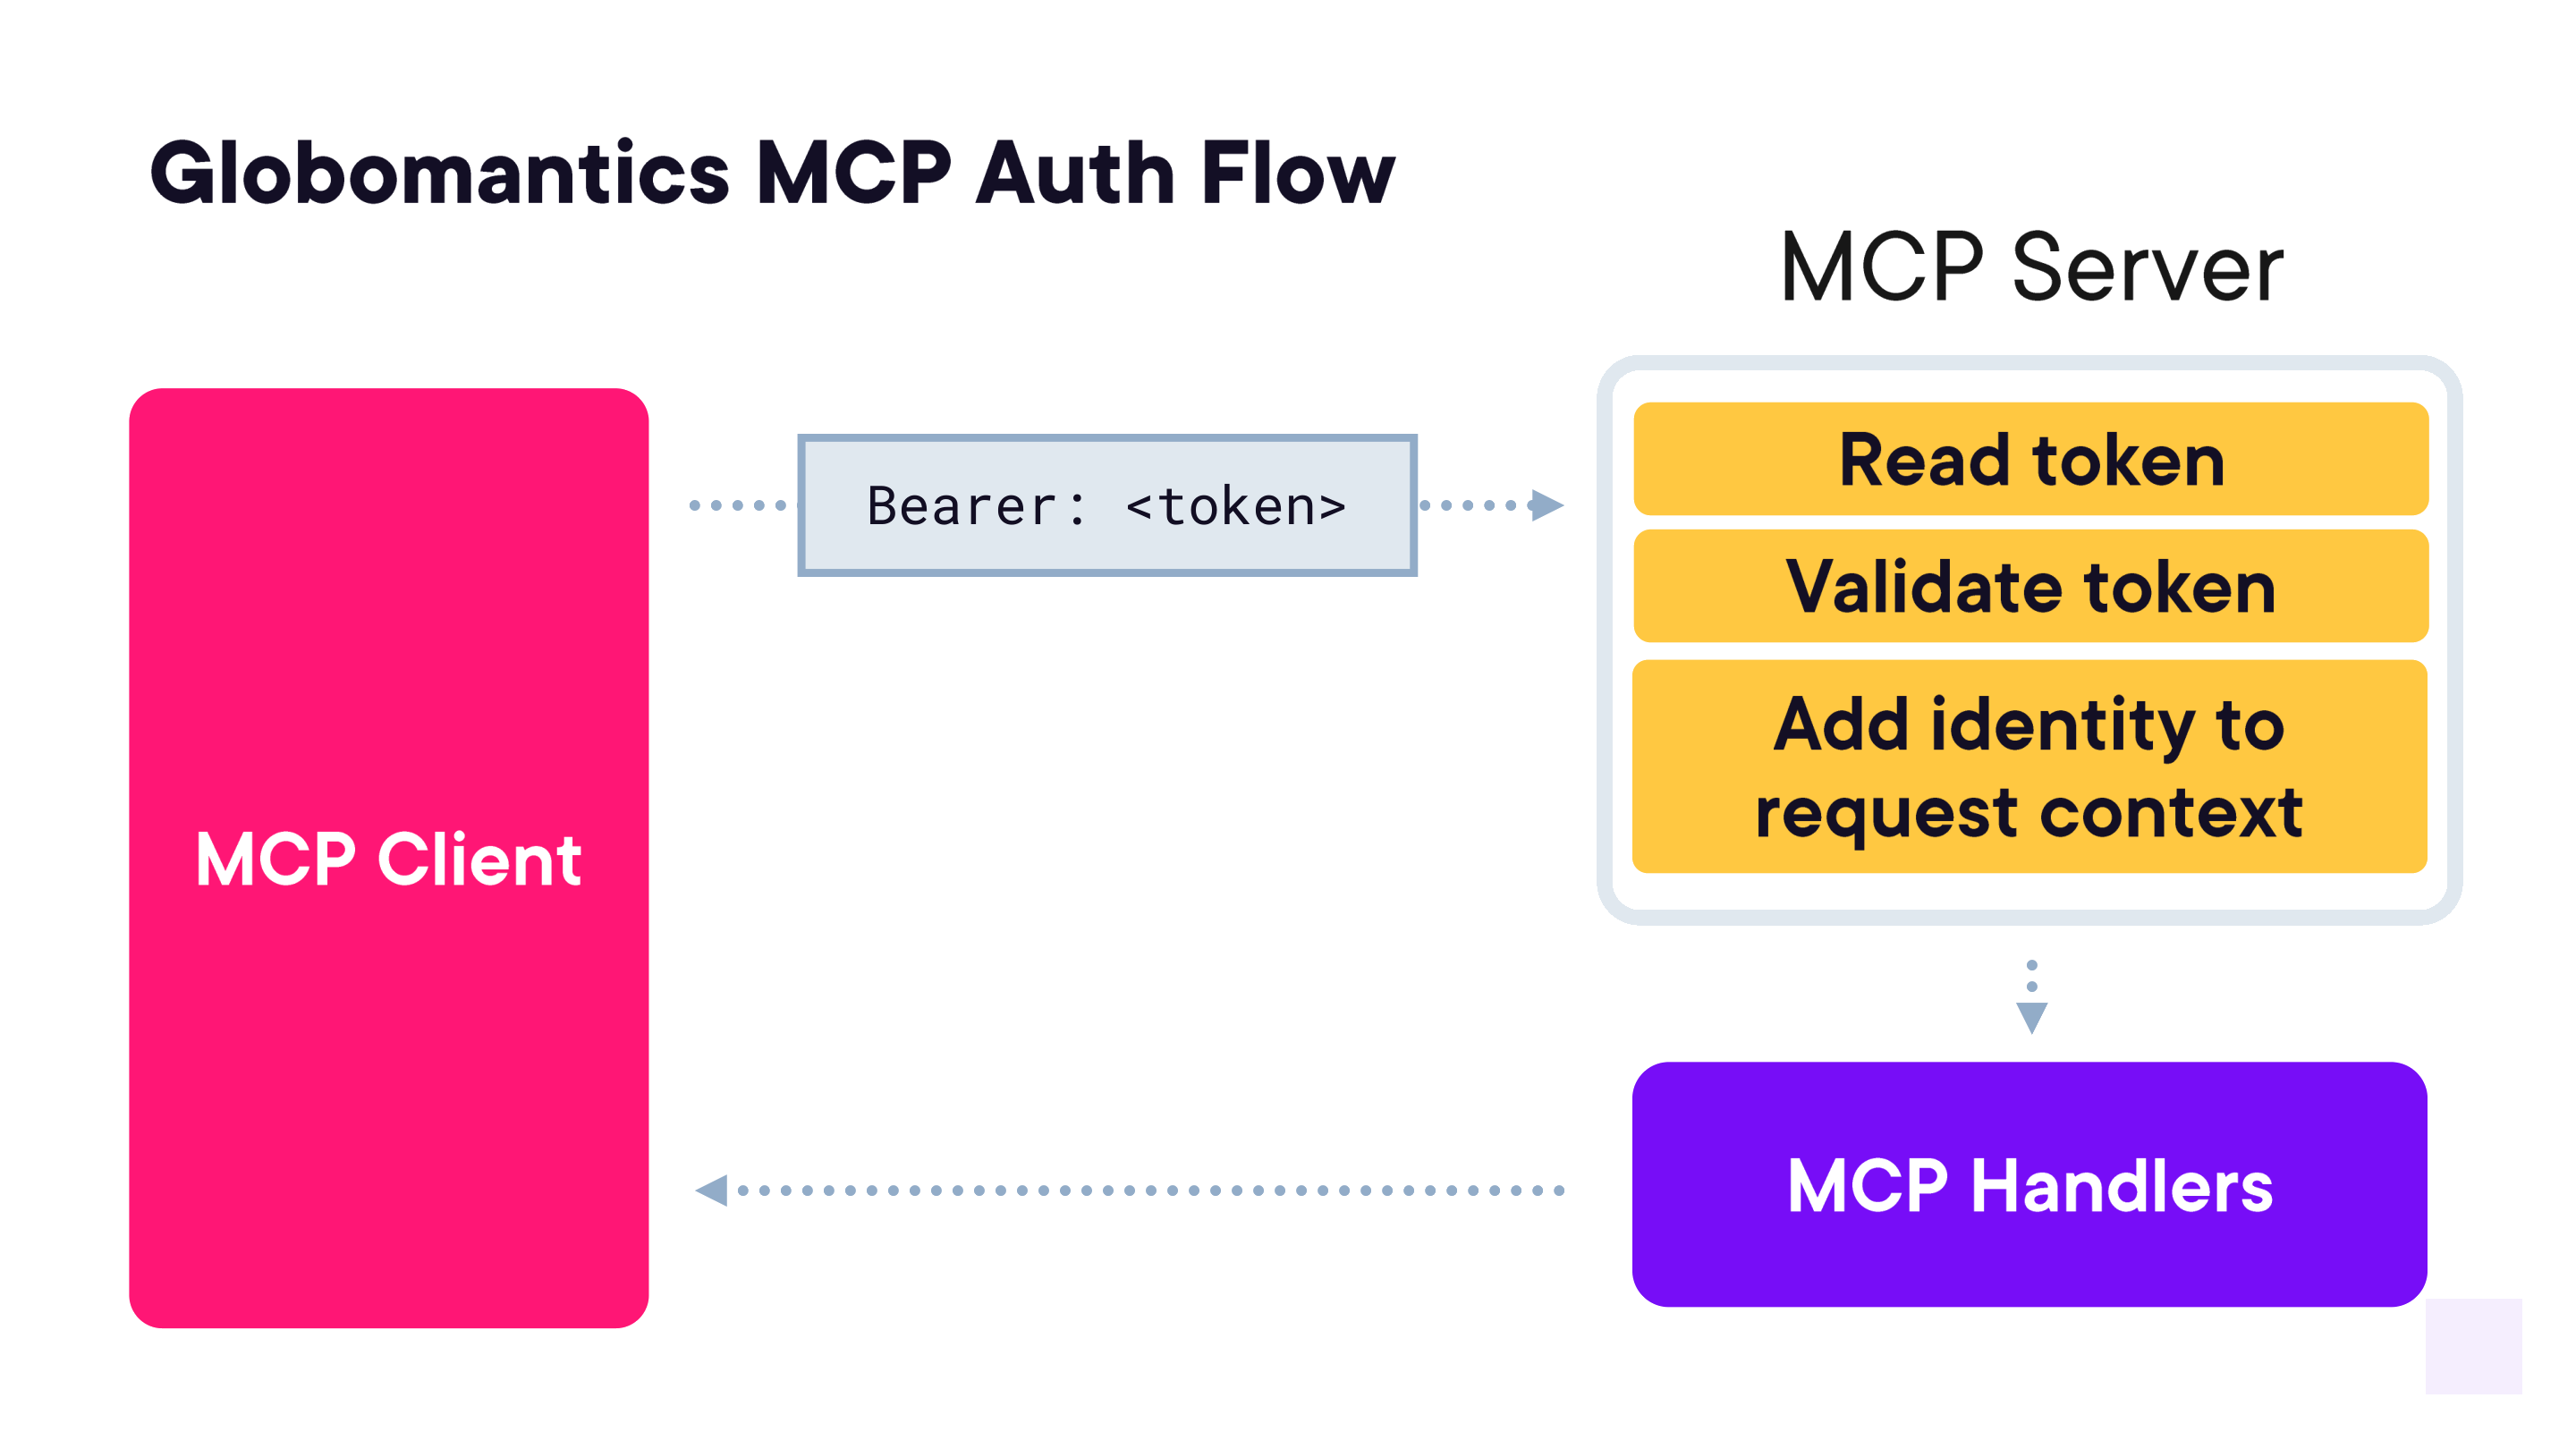

In [11]:
render_diagram(Path("assets/11-mcp-auth-flow.png"))

The MCP client sends a `Bearer: <token>` header with every request. The server's auth middleware reads, validates, and extracts the identity from the token, then adds it to the request context before the MCP handlers execute.

### Hosting with Azure Functions

When hosted on Azure Functions, the Functions runtime acts as a reverse proxy in front of the application. Requests arrive at a public domain (`mcp.globomantics.org`) or Azure hostname, the runtime forwards them to the app process on localhost:


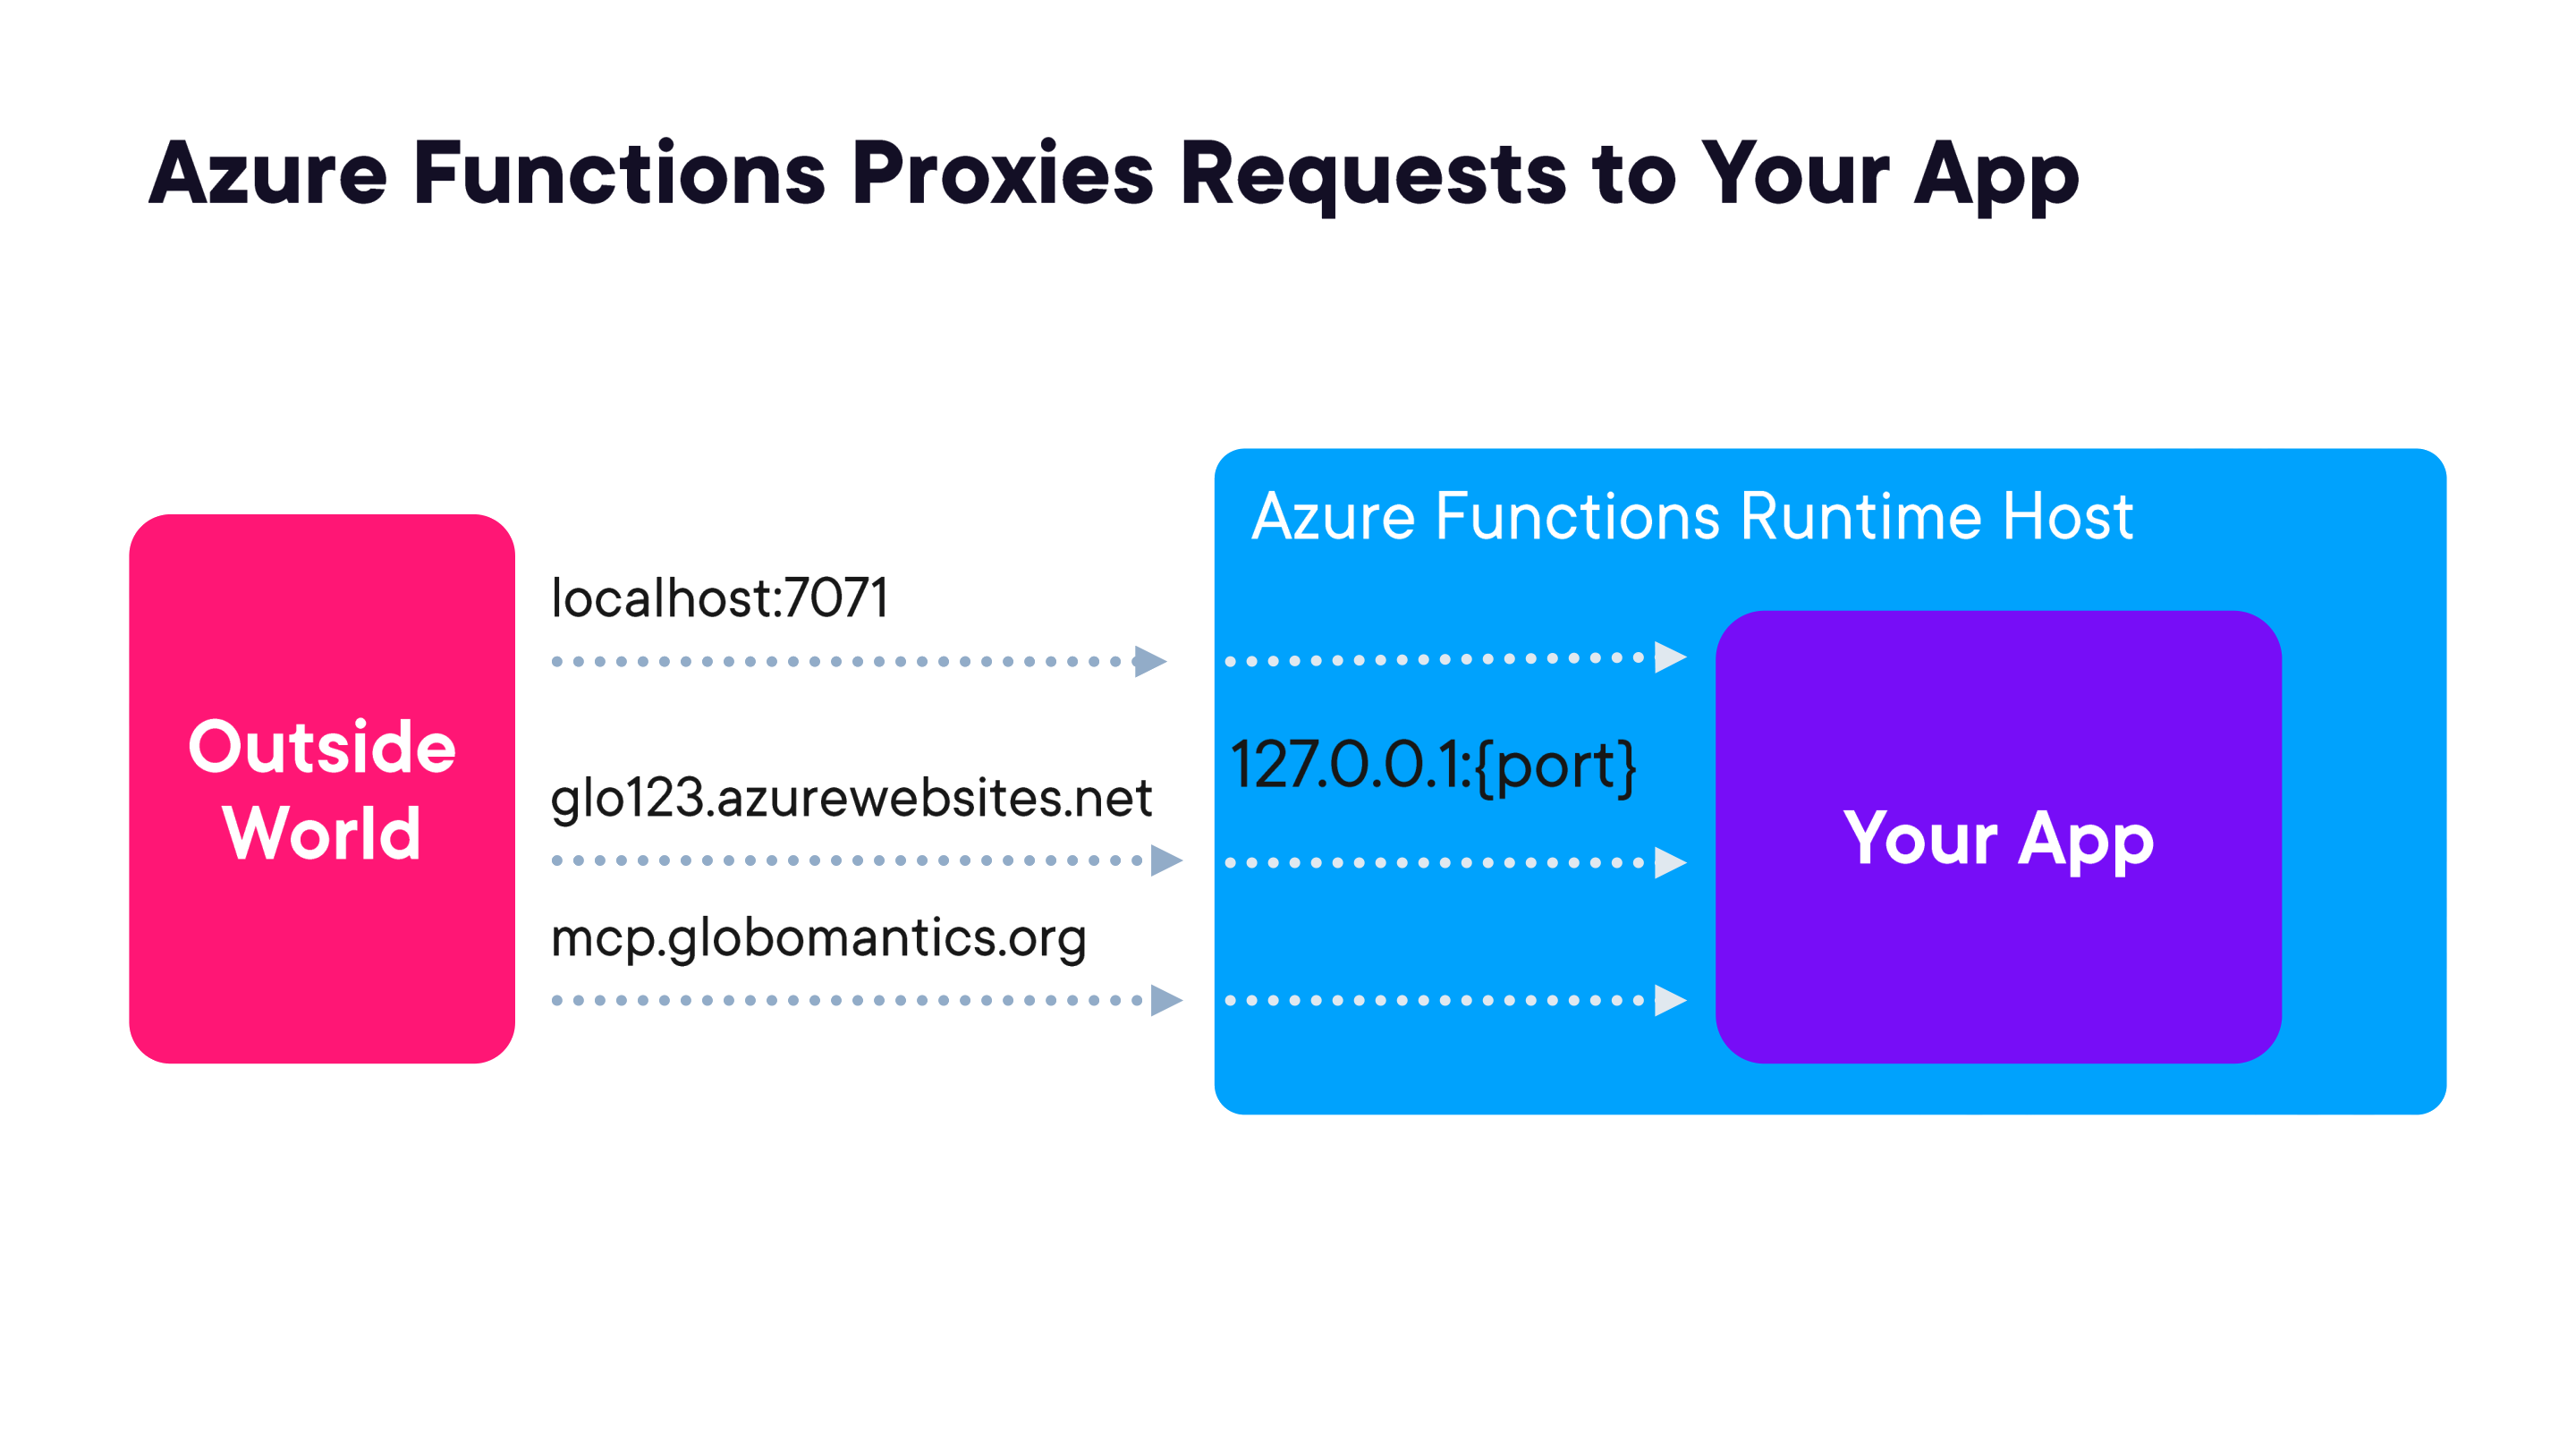

In [12]:
render_diagram(Path("assets/12-azure-functions-proxy.png"))

#### Forwarding Headers

Because the Functions runtime sits in front, the application sees `localhost:7071` as the host. To expose the real public URL (needed for OAuth metadata), configure the proxy to forward original request headers:

```
X-Forwarded-Host: localhost:7071
X-Forwarded-Proto: http
X-Forwarded-For: 66.7.88.134
```

The application reads these headers to construct absolute URLs for OAuth metadata documents.

### Protected Resource Metadata (PRM)

The MCP authorization spec requires the server to publish a **Protected Resource Metadata** document at `/.well-known/oauth-protected-resource`. This document tells OAuth clients where to obtain tokens and what scopes are required.

Example PRM document:

```json
{
  "resource": "https://globomantics.com/mcp",
  "authorization_servers": [
    "https://login.microsoftonline.com/tenant-id/v2.0"
  ],
  "scopes_supported": [
    "api://app-client-id/user_impersonation"
  ],
  "bearer_methods_supported": [
    "header"
  ],
  "resource_documentation": "https://globomantics.com/mcp"
}
```

Reference: `modelcontextprotocol.io/specification/2025-06-18/basic/authorization`

#### CORS Policy

> A browser-based security mechanism that prevents cross-origin requests from being served unless the client satisfies a policy defined on the server. This only applies to requests initiated using the JavaScript `fetch` API and images or asset links.

For MCP servers that support browser-based clients, the CORS policy must allow the client's origin.

### Client Registration

MCP clients must register with the OAuth authorization server before they can obtain tokens.

#### Static Client Registration

For a known, fixed set of clients (e.g. web app, iOS app, Android app), register each client once in the OAuth configuration. This is simple but requires knowing all clients in advance.

#### Dynamic Client Registration

For open MCP ecosystems where many agentic tools may connect (VS Code, Cursor, Claude, ChatGPT, custom clients), requiring manual registration introduces friction. **Dynamic Client Registration** allows clients to register themselves at runtime — the client calls a registration endpoint and receives a `client_id` in response.

The trade-off: dynamic registration requires careful security controls (rate limiting, token binding) to prevent abuse.

### JWT Bearer Authentication

The server validates incoming bearer tokens as JWTs. Validation checks:
- Signature (using the authorization server's public key)
- Issuer (`iss` claim matches the expected authorization server)
- Audience (`aud` claim matches the server's resource identifier)
- Expiry (`exp` claim)
- Scopes required for the operation

### Passing Auth Context into Tool Handlers


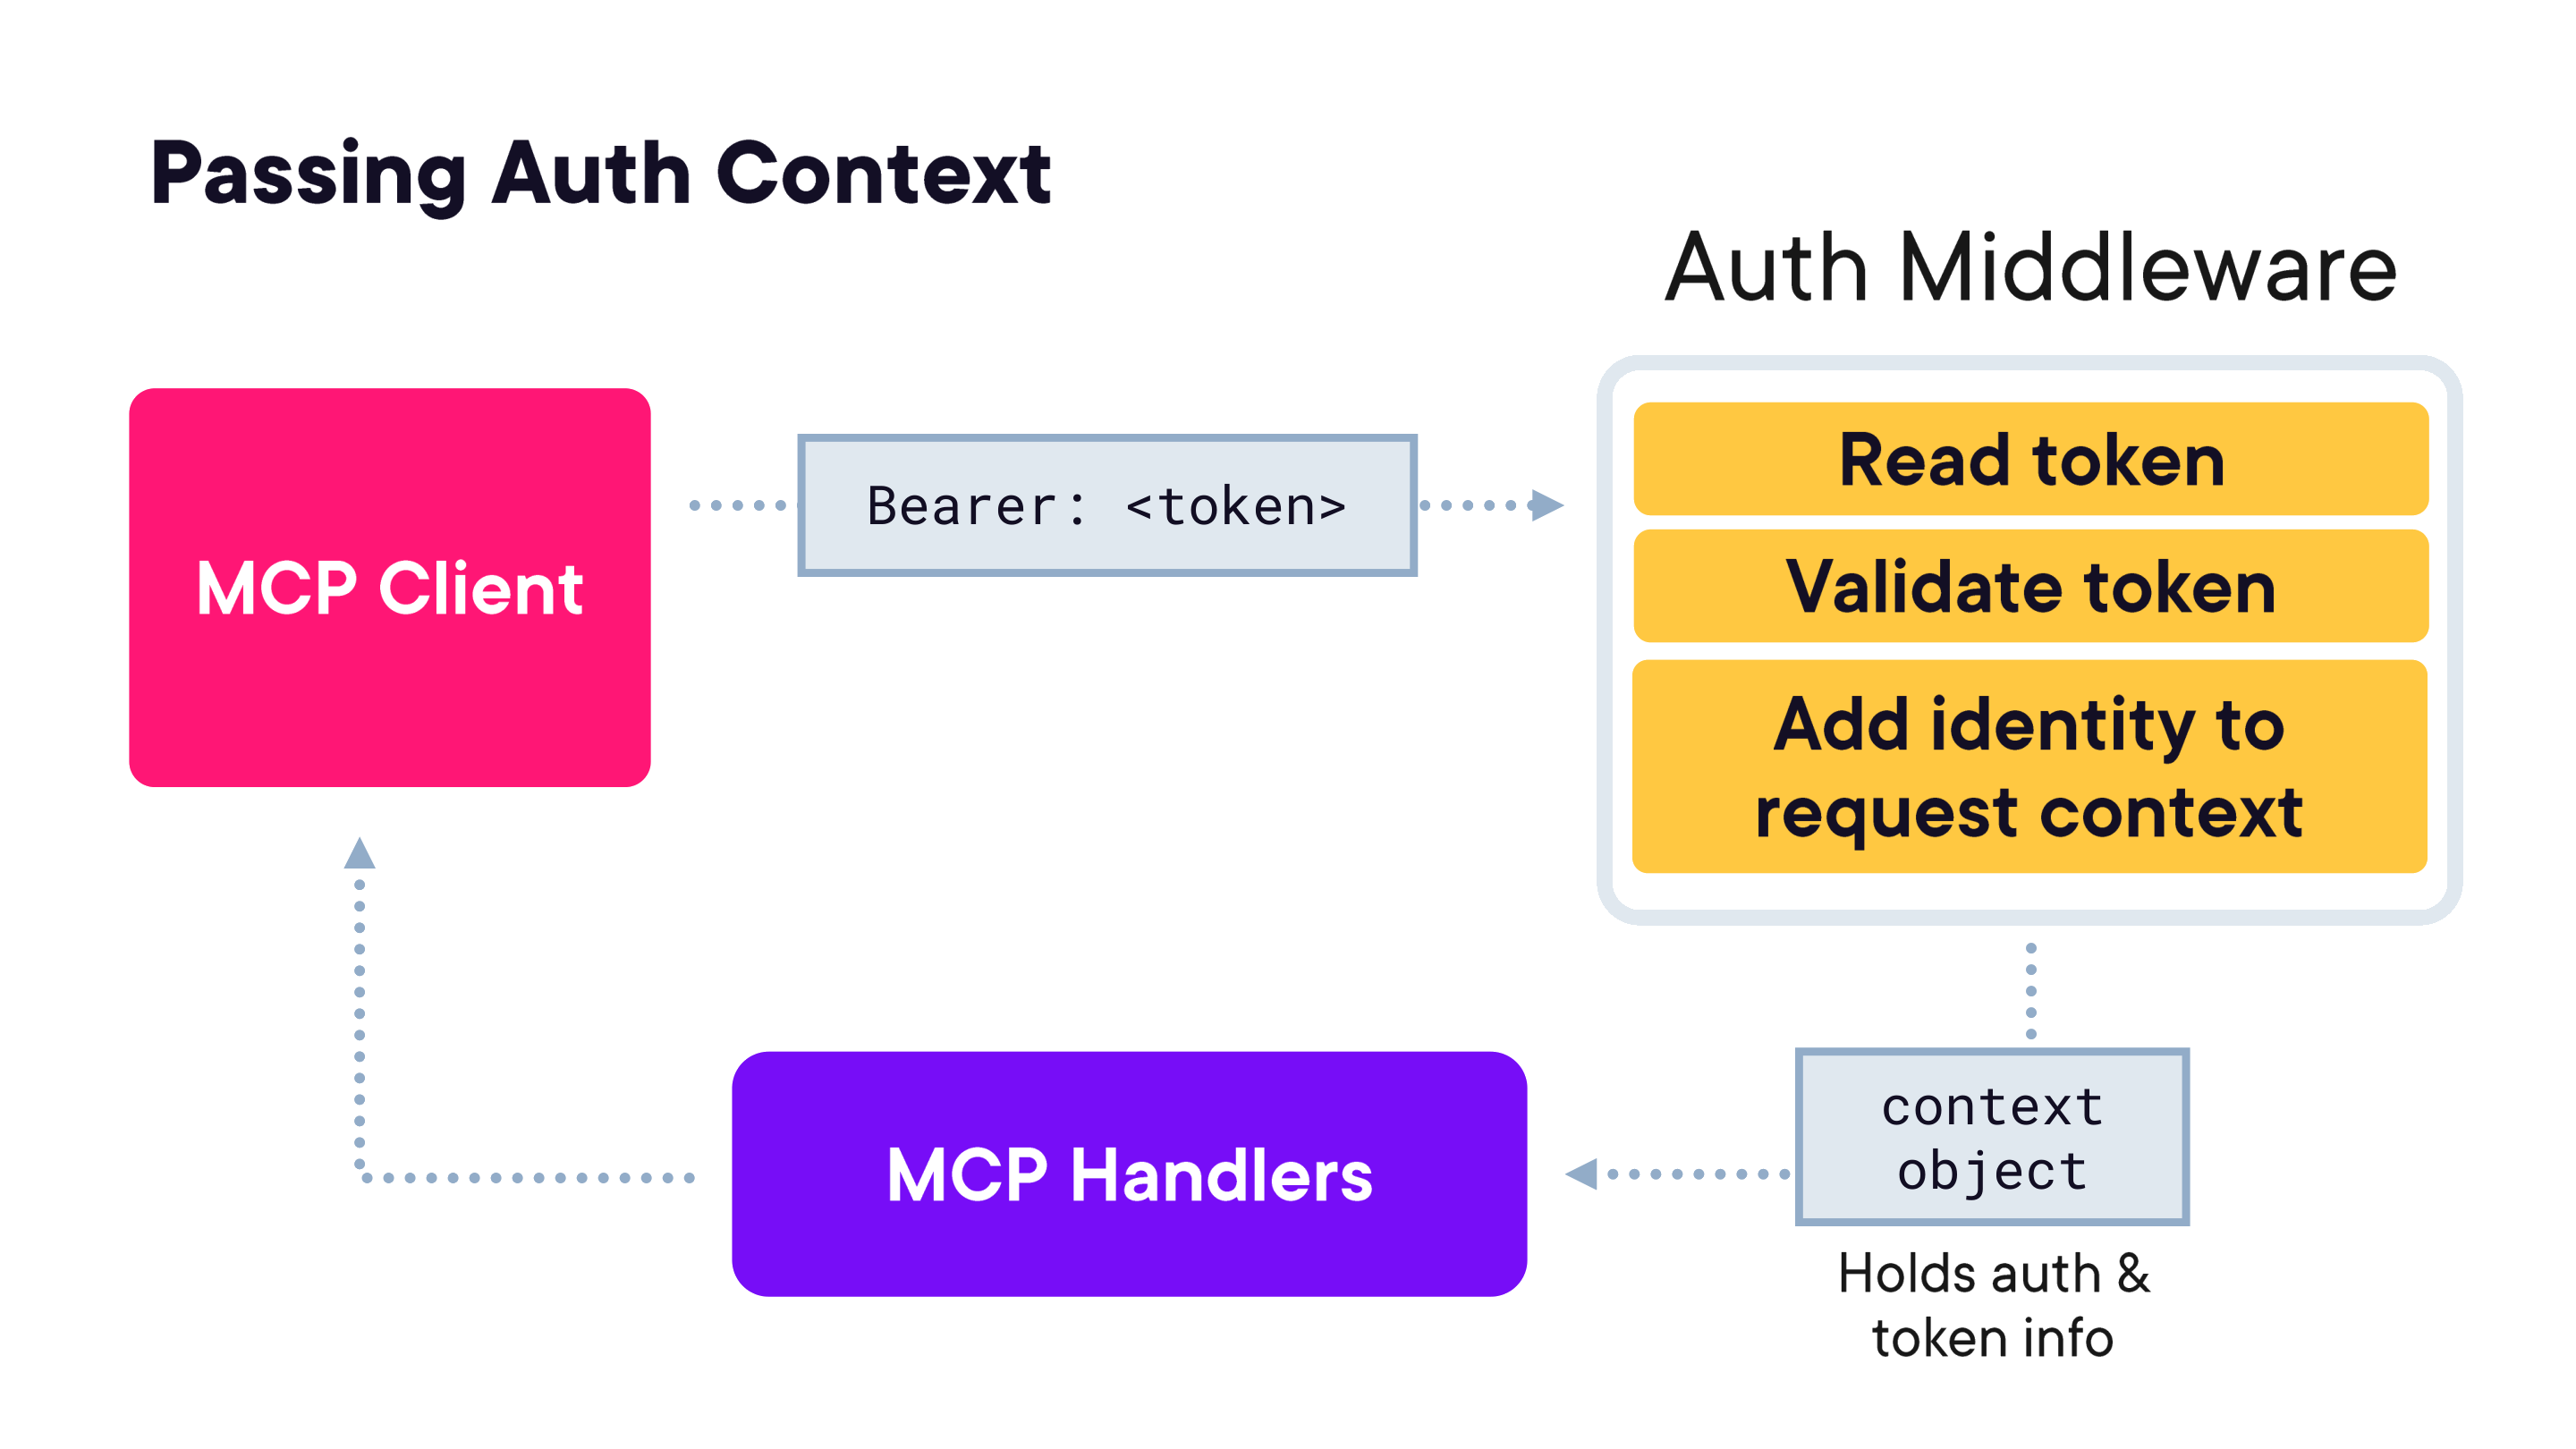

In [13]:
render_diagram(Path("assets/13-auth-context-passing.png"))

The auth middleware populates a `context object` that holds the auth info and decoded token claims. MCP handlers receive this context object and use it to look up the authenticated user's identity.

#### Accessing Auth Context in TypeScript

In [14]:
typescript_auth_example = """
import { RequestHandlerExtra } from '@modelcontextprotocol/sdk/shared/protocol';
import {
  CallToolResult,
  ServerNotification,
  ServerRequest,
} from '@modelcontextprotocol/sdk/types';

const toolCallHandler: Promise<CallToolResult> =
  async (args, req: RequestHandlerExtra<ServerRequest, ServerNotification>) => {
    const userId = req.authInfo?.extra?.userId || ''
    // use userId to scope HRM API calls to the authenticated employee
  }
"""
print(typescript_auth_example)


import { RequestHandlerExtra } from '@modelcontextprotocol/sdk/shared/protocol';
import {
  CallToolResult,
  ServerNotification,
  ServerRequest,
} from '@modelcontextprotocol/sdk/types';

const toolCallHandler: Promise<CallToolResult> =
  async (args, req: RequestHandlerExtra<ServerRequest, ServerNotification>) => {
    const userId = req.authInfo?.extra?.userId || ''
    // use userId to scope HRM API calls to the authenticated employee
  }



### Fixing the Security Hole

With authentication in place, all server capabilities operate under the **authenticated user context**. The employee ID no longer comes from caller-supplied input — it is read from the validated JWT token. This closes the vulnerability where any caller could impersonate any employee.

The final server blueprint, now secured:

| Resources | Tools | Prompts |
|---|---|---|
| Calendars | Request Time Off | Suggest Time Off |
| Documents | Plan Time Off | Next Scheduled Holiday |
| | Ask About Policy | |
| **Authenticated User Context spans all columns** | | |

### Course Summary

Key takeaways:

- **Local MCP servers** are a good fit for many use cases, especially for developers and power users
- **MCP servers can be secured** just like any other backend server — OAuth 2.1 is the standard path
- **Model performance is only as good as the context you provide** — context engineering is the core discipline
- **MCP is not just an API** — it is a new frontend for agentic tools that need contextual UX

### References

- MCP authorization spec: `modelcontextprotocol.io/specification/2025-06-18/basic/authorization`
- Azure Functions MCP hosting (.NET): `github.com/Azure-Samples/mcp-sdk-functions-hosting-dotnet`
- C# SDK protected server sample: `github.com/modelcontextprotocol/csharp-sdk/blob/main/samples/ProtectedMcpServer`
- .NET user-assigned managed identity: `learn.microsoft.com/en-us/dotnet/azure/sdk/authentication/user-assigned-managed-identity`